<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** uRNA structures of the Atera breast cancer ROI: DRVI, structure types, parent cells, Vesiclepedia ORA.
> - **Manuscript panels:** ED Fig. 4B-F
> - **Inputs:** Annotated atera_hsbreast zarr
> - **Outputs:** Structure-annotated zarr and figures
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

We employ this notebook to perform DRVI on segmented structures 

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData

import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

from typing import Any

import anndata
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import seaborn as sns
from anndata import AnnData
from matplotlib import gridspec, rcParams
from spatialdata import SpatialData  # Assuming SpatialData is from scverse
from troutpy.pl.colors import get_colormap
import numpy as np
import sys
import seaborn as sns
from pathlib import Path




#import hotspot

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_te

In [2]:
import anndata as ad
import scanpy as sc
from matplotlib import pyplot as plt
from IPython.display import display
#from gprofiler import GProfiler

import drvi
from drvi.model import DRVI
from drvi.utils.misc import hvg_batch

In [3]:
import sys
import os 

# Import local pipeline submodules directly
from troutpy import pl
from troutpy import tl
from troutpy import pp

In [4]:
import sys
import os 

from troutpy_reproducibility.plotting import *
from troutpy_reproducibility.ora_analysis import *
from troutpy_reproducibility.downstream import *

In [5]:
# Define base directories
data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/atera_hsbreast")
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/atera_hsbreast")


In [ ]:

# Read spatial data using the / operator for clean path joining
sdata = sd.read_zarr(data_dir / "data_with_source_score.zarr")

# Redo binsize selection and segmentation free

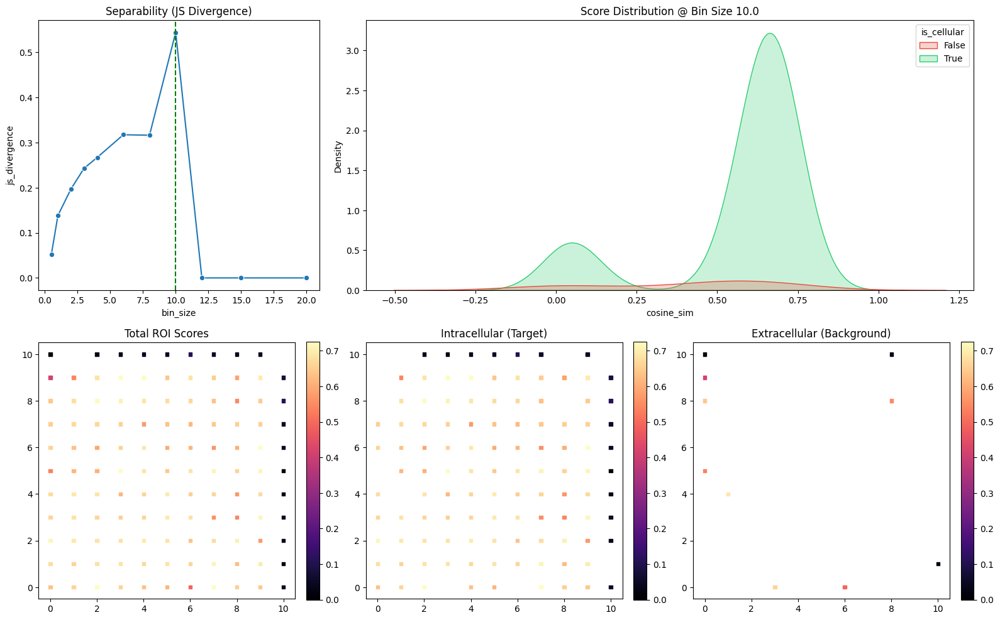

In [6]:
results, met_df, binsize_selected = pp.find_optimal_segmentation_free_bin_size(
    sdata, bin_sizes=[0.5, 1, 2, 3, 4, 6, 8, 10, 12, 15, 20], roi_size=100)

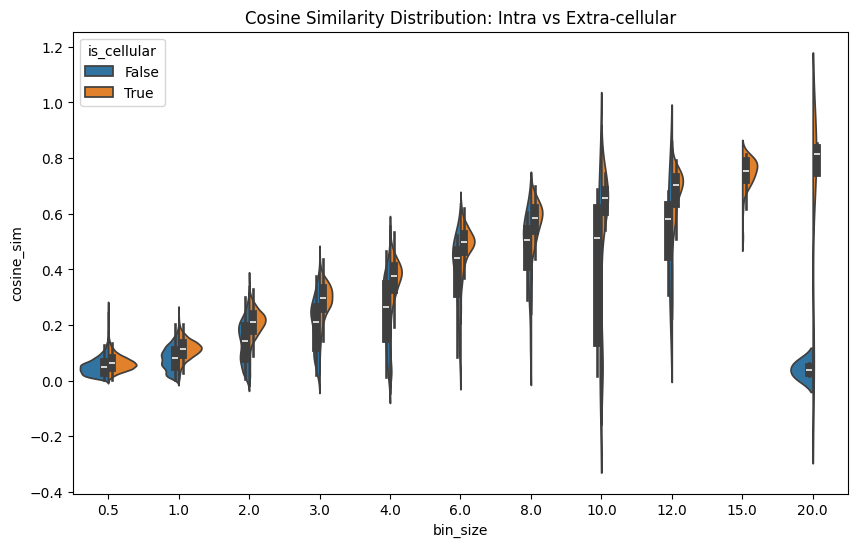

Saved optimal bin size violin plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/atera_hsbreast/cosine_similarity_distribution.png


In [8]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=results, x="bin_size", y="cosine_sim", hue="is_cellular", split=True)
plt.title("Cosine Similarity Distribution: Intra vs Extra-cellular")

violin_out_path = os.path.join(saving_path, "cosine_similarity_distribution.png")
plt.savefig(violin_out_path, bbox_inches='tight', dpi=300)
plt.show()
print(f"Saved optimal bin size violin plot to: {violin_out_path}")

In [23]:
# Segmentation-free SAiNSC using local modules
pp.segmentation_free_sainsc(
    sdata, binsize=1.0, celltype_key="leiden", 
    background_filter=0.4, gaussian_kernel_key=1.0, 
    n_threads=8)

In [24]:
import numpy as np
from scipy.stats import gaussian_kde
import spatialdata as sd

# --- Configuration Parameters ---
p_threshold = 0.5

# --- Step 1: Extract and Compute Data ---
# Extract transcripts dataframe from your existing sdata object
df = sdata.points["transcripts"].compute()

# --- Step 2: Define Reference Populations ---
# Reference populations: transcripts inside cells vs. background transcripts outside cells
mask_inside = df["overlaps_cell"]
mask_outside = ~df["overlaps_cell"] & (df["enrichment_class"] == "Moderate Density")

scores_in = df.loc[mask_inside, "cosine_similarity"].dropna().values
# Note: If your data does not have 'enrichment_class', drop that condition or 
# use: scores_out = df.loc[~df["overlaps_cell"], "cosine_similarity"].dropna().values
scores_out = df.loc[mask_outside, "cosine_similarity"].dropna().values

# --- Step 3: Guard against insufficient data ---
if len(scores_in) < 10 or len(scores_out) < 10:
    print(f"Warning: Insufficient data for KDE. Found inside: {len(scores_in)}, outside: {len(scores_out)}.")
else:
    # --- Step 4: Fit Kernel Density Estimations (KDE) ---
    kde_in = gaussian_kde(scores_in)
    kde_out = gaussian_kde(scores_out)

    # --- Step 5: Evaluate on Grid & Calculate Bayesian Probability ---
    all_scores = df["cosine_similarity"].values
    valid_mask = np.isfinite(all_scores)
    actual_scores = all_scores[valid_mask]

    # Create grid spanning the entire range of cosine similarity scores
    grid = np.linspace(np.nanmin(all_scores), np.nanmax(all_scores), 500)
    
    li_in_grid = kde_in(grid)
    li_out_grid = kde_out(grid)
    
    # P(uRNA | score) calculation
    prob_grid = li_out_grid / (li_out_grid + li_in_grid + 1e-10)

    # --- Step 6: Map Grid Probabilities Back onto Every Transcript ---
    prob_is_urna = np.full(len(df), np.nan)
    prob_is_urna[valid_mask] = np.interp(actual_scores, grid, prob_grid)

    df["prob_is_urna"] = prob_is_urna
    df["extracellular"] = ~df["overlaps_cell"] & (df["prob_is_urna"] > p_threshold)

    # --- Step 7: Push Modified Layer Back into sdata ---
    # Updates the 'transcripts' layer of your existing sdata object in-place
    sdata.points["transcripts"] = sd.models.PointsModel.parse(df)
    print("Successfully calculated uRNA probability and updated sdata['transcripts'].")

Successfully calculated uRNA probability and updated sdata['transcripts'].


In [25]:
pp.define_urna(sdata, method='sainsc')

Defined 5115510 URNA transcripts using Bayesian P > 0.5


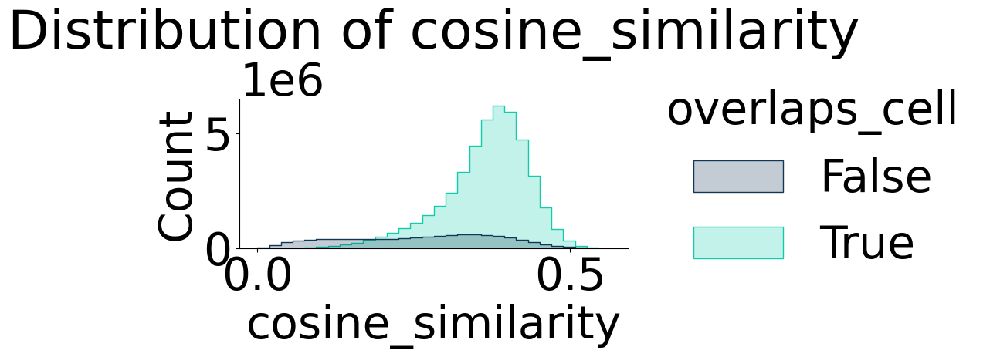

In [26]:
pl.histogram(sdata, x="cosine_similarity", hue="overlaps_cell", palette="troutpy")

(<Figure size 800x800 with 2 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

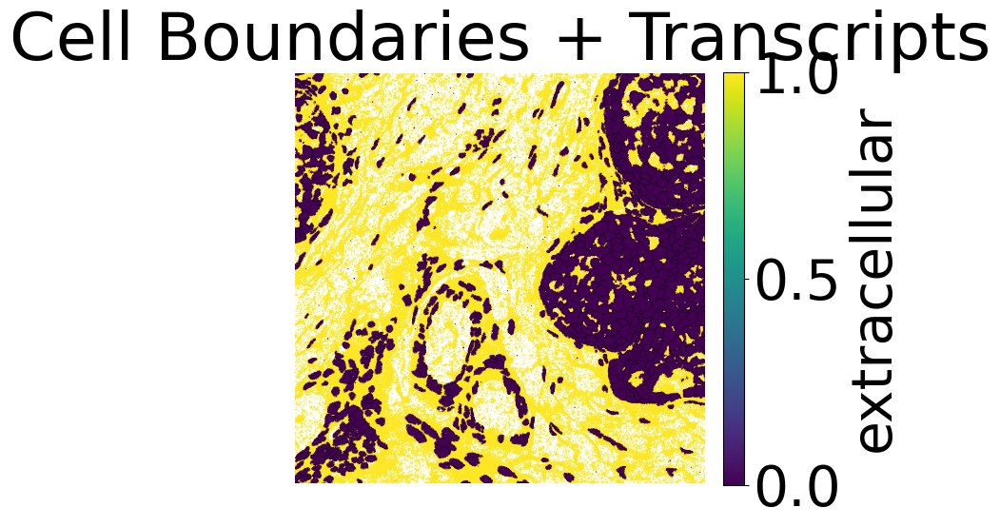

In [27]:
# Plots clusters using discrete colors from the categorical 'tab20' palette
pl.spatial_transcripts(sdata, scatter_size=0.5,use_roi=True,roi=(4500,5000,2200,2700),color_key='extracellular')
#fig1.savefig("leiden_clusters.png", bbox_inches='tight')

In [28]:
tl.segment_protrusions(
    sdata, n_neighbors=10, cluster_eps=2.0, 
    connectivity_threshold=4.0, min_samples=1)


--- Step 1: Extracting structures from 'transcripts' ---
--- Step 2: Computing morphology and metrics ---
--- Step 3: Assignment logic for 21488 structures ---


Analyzing Parents: 100%|██████████| 21488/21488 [00:26<00:00, 804.27it/s]


--- Step 4: Updating sdata ---
Success! Registered 'structure_table' with morphological and parent metrics.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

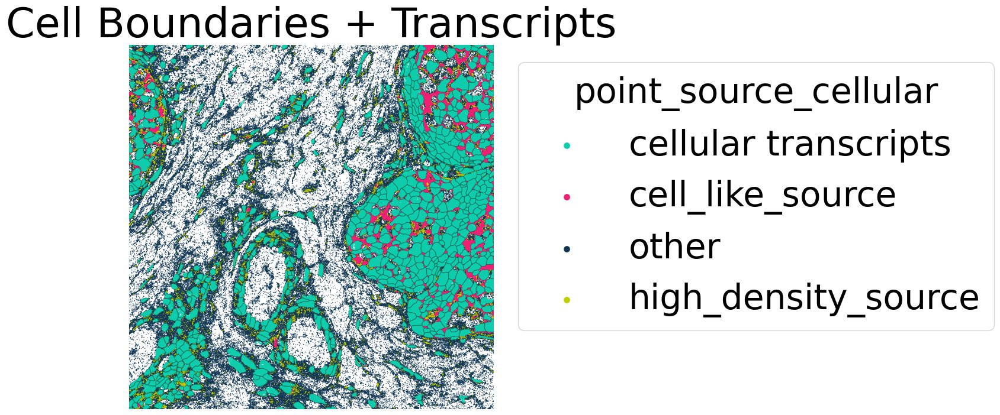

In [29]:
# Plots clusters using discrete colors from the categorical 'tab20' palette
pl.spatial_transcripts(sdata, scatter_size=0.5,use_roi=True,roi=(4500,5000,2200,2700))
#fig1.savefig("leiden_clusters.png", bbox_inches='tight')

In [30]:
sdata.write(data_dir / "data_with_source_score_optimized_params.zarr")

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/atera_hsbreast/data_with_source_score_
         optimized_params.zarr). Please see the documentation of `is_self_contained()` to understand the           
         implications of working with SpatialData objects that are not self-contained.                             
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/atera_hsbreast/data_with_source_score.
         zarr the new file path:                                                                                   
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/

# Quantify structures by are and by counts

In [ ]:
sdata=sd.read_zarr(data_dir / "data_with_source_score_optimized_params.zarr")

# Step 1: Run calculations and print statistics table
qc_data = compute_transcript_distributions(sdata=sdata, cell_table_key="table", fragment_table_key="structure_table")

Saved → ./fig1_transcript_ranges.pdf
Saved → ./fig2_transcript_histogram.pdf
Saved → ./fig3_transcript_cdf.pdf


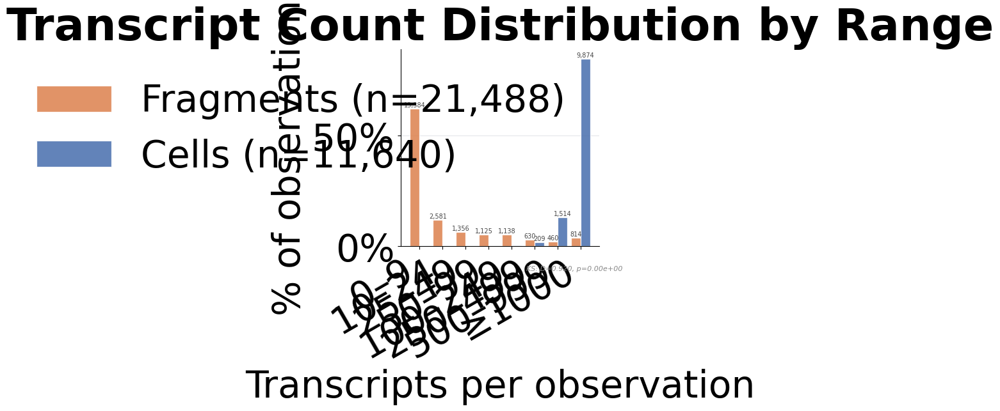

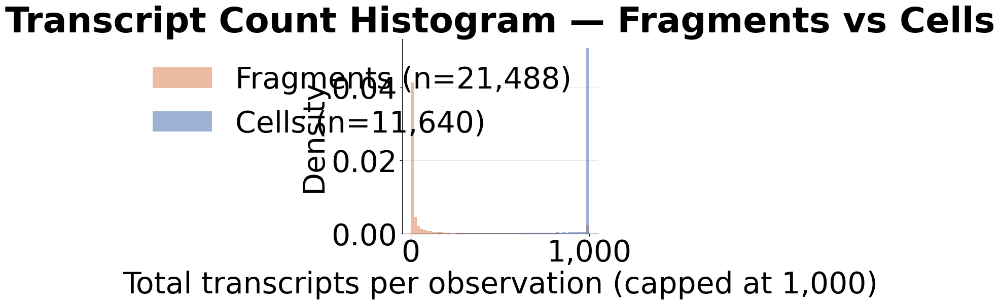

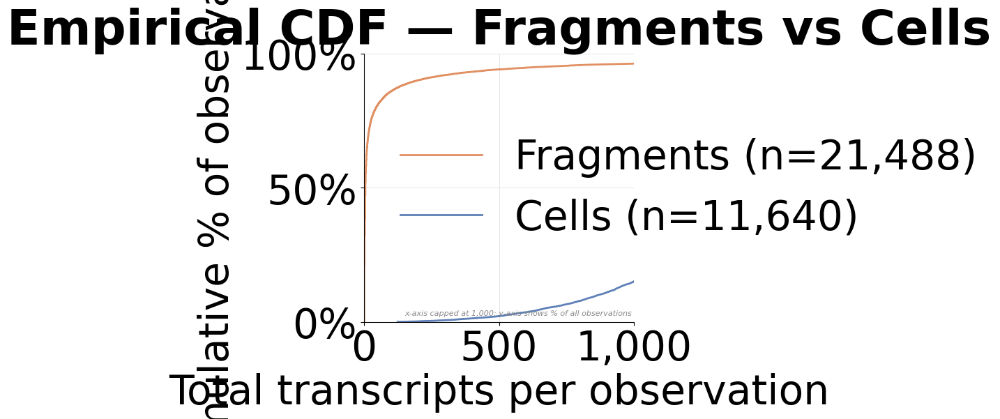

In [33]:
# Mode 1: Default behaves exactly as before, spitting out all three plots
plot_transcript_distributions(data_dict=qc_data, mode="all")

# Do DRVI

In [35]:
# We filter structure table
sc.pp.filter_cells(sdata['structure_table'],min_counts=5)
sc.pp.filter_cells(sdata['structure_table'],min_genes=2)
#sc.pp.filter_genes(sdata['structure_table'],min_cells=50)

In [36]:
sdata['structure_table'].layers['counts']=sdata['structure_table'].X

# Setup data
DRVI.setup_anndata( sdata['structure_table'],layer="counts",is_count_data=True,)

# construct the model
model = DRVI(sdata['structure_table'],
    # Provide categorical covariates keys once again. Refer to advanced usages for more options.
    #categorical_covariates=["batch"],
    n_latent=128,
    # For encoder and decoder dims, provide a list of integers.
    encoder_dims=[128, 128],
    decoder_dims=[128, 128])


INFO     DRVI: The model has been initialized                                                                      


We next train the DRVI model

In [37]:
n_epochs = 400

# train the model
model.train(
    max_epochs=n_epochs,
    early_stopping=False,
    early_stopping_patience=20,
    plan_kwargs={ "n_epochs_kl_warmup": n_epochs, },)

# Runtime:
# The runtime for CPU laptop (M1) is 208 minutes
# The runtime for Macbook gpu (M1) is 64 minutes
# The runtime for GPU (A100) is 17 minutes

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-PCIE-40GB MIG 3g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-3acbc457-82bc-59c2-a4db-9fd26324b7db]
SLURM auto-requeueing enabled. Setting signal handlers.


Epoch 400/400: 100%|██████████| 400/400 [48:36<00:00,  7.44s/it, v_num=1, train_loss_step=275, train_loss_epoch=857]    

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [48:36<00:00,  7.29s/it, v_num=1, train_loss_step=275, train_loss_epoch=857]


In [38]:
# Save the model
model.save("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/atera_hsbreast/drvi_general_pipeline_hsbreast", overwrite=True)

# Load again DRVI

In [6]:
sdata=sd.read_zarr(data_dir / "data_with_source_score_optimized_params.zarr")
sdata['structure_table'].layers['counts']=sdata['structure_table'].X
adata=sdata['structure_table']

In [7]:
import torch

def torch_load_weights_only_false(*args, **kwargs):
    kwargs["weights_only"] = False
    return orig_torch_load(*args, **kwargs)

orig_torch_load = torch.load
torch.load = torch_load_weights_only_false

# Load the model
model = DRVI.load("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/atera_hsbreast/drvi_general_pipeline_hsbreast",adata)

INFO     File                                                                                                      
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/atera_hsbreast/drvi_general_pipeline_
         hsbreast/model.pt already downloaded                                                                      
INFO     DRVI: The model has been initialized                                                                      


In [8]:
embed = ad.AnnData(model.get_latent_representation(), obs=sdata['structure_table'].obs)
embed.obsm['spatial']=sdata['structure_table'].obsm['spatial']

In [9]:
sc.pp.neighbors(embed, n_neighbors=7, use_rep="X", n_pcs=embed.X.shape[1])
sc.tl.umap(embed, spread=1.0, min_dist=0.01, random_state=123)
sc.tl.leiden(embed,key_added='urna_cluster',resolution=0.4)
drvi.utils.tl.set_latent_dimension_stats(model, embed,vanished_threshold=1)
print(embed.var.sort_values("reconstruction_effect", ascending=False))

     original_dim_id  reconstruction_effect  order  max_value      mean  \
18                18           6.128293e+07      0   2.645679 -0.127458   
22                22           3.165527e+07      1   3.270833 -0.034916   
99                99           2.547831e+07      2   3.404217  0.008433   
13                13           1.834080e+07      3   3.713907  0.002218   
101              101           1.732810e+07      4   3.536783  0.023461   
..               ...                    ...    ...        ...       ...   
126              126           1.320152e+06    123   0.017907  0.000531   
90                90           1.320151e+06    124   0.014614  0.000600   
31                31           1.320144e+06    125   0.019560 -0.000663   
102              102           1.320143e+06    126   0.011511  0.001101   
104              104           1.320127e+06    127   0.016434 -0.000553   

          min       max       std   title  vanished  
18  -2.645679  2.574586  0.469573    DR 1    

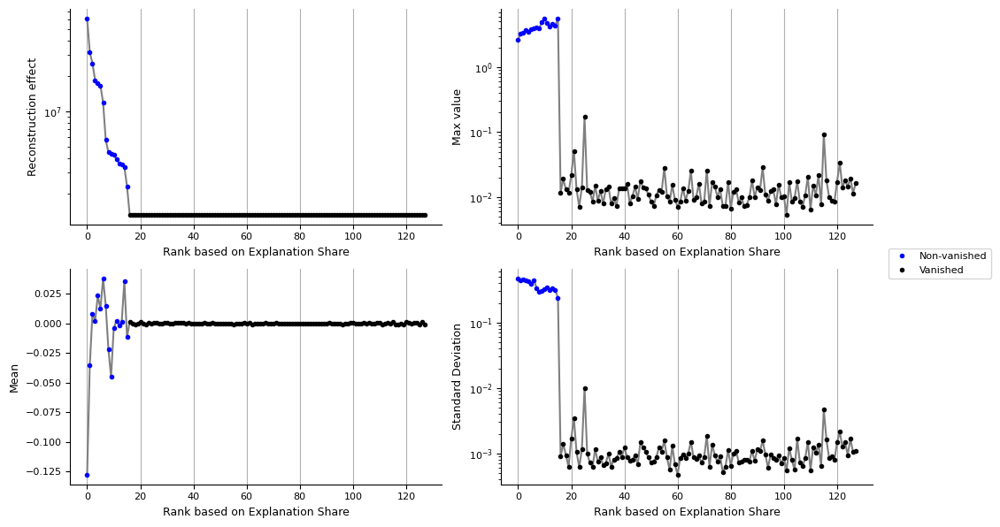

In [10]:
import matplotlib.pyplot as plt
import os

# 1. Scale down the font sizes globally for this plot
plt.rcParams.update({
    'font.size': 8,          # General font size
    'axes.labelsize': 9,     # X and Y label size
    'axes.titlesize': 10,    # Subplot title size
    'xtick.labelsize': 8,    # X-axis tick size
    'ytick.labelsize': 8,    # Y-axis tick size
    'legend.fontsize': 8     # Legend font size (if applicable)
})

# 2. Run your plotting function
drvi.utils.pl.plot_latent_dimension_stats(embed, ncols=2, show=False)

# 3. Save with bbox_inches='tight' to prevent labels from getting cut off
plt.savefig(
    os.path.join(saving_path, 'latent_dimension_stats_all.pdf'), 
    bbox_inches='tight'
)

# 4. (Optional) Reset to default styles so later plots aren't affected
plt.rcParams.update(plt.rcParamsDefault)

In [11]:
drvi.utils.pl.plot_latent_dimension_stats(embed, ncols=2,show=False)
plt.savefig(os.path.join(saving_path,'latent_dimension_stats_all.pdf'))

In [12]:
drvi.utils.pl.plot_latent_dimension_stats(embed, ncols=2, remove_vanished=True,show=False)
plt.savefig(os.path.join(saving_path,'latent_dimension_stats.pdf'))

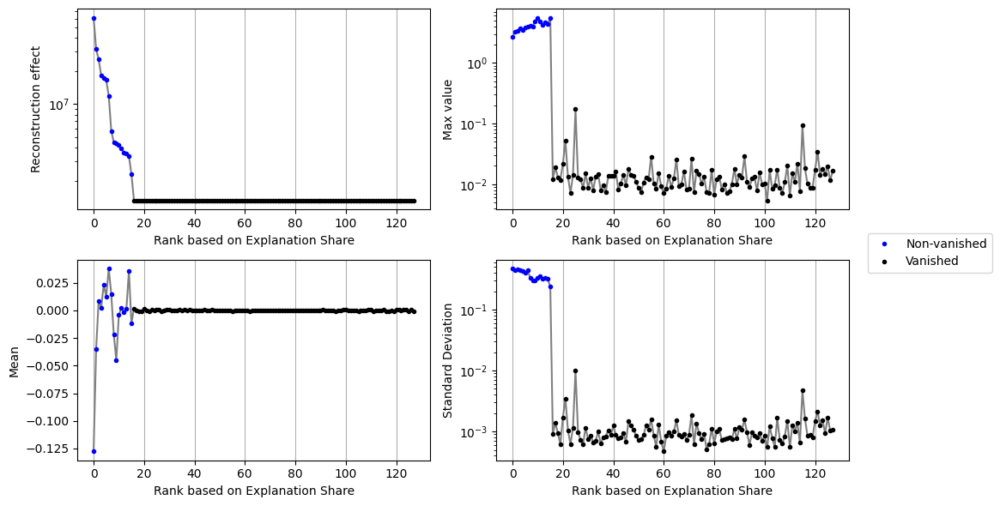

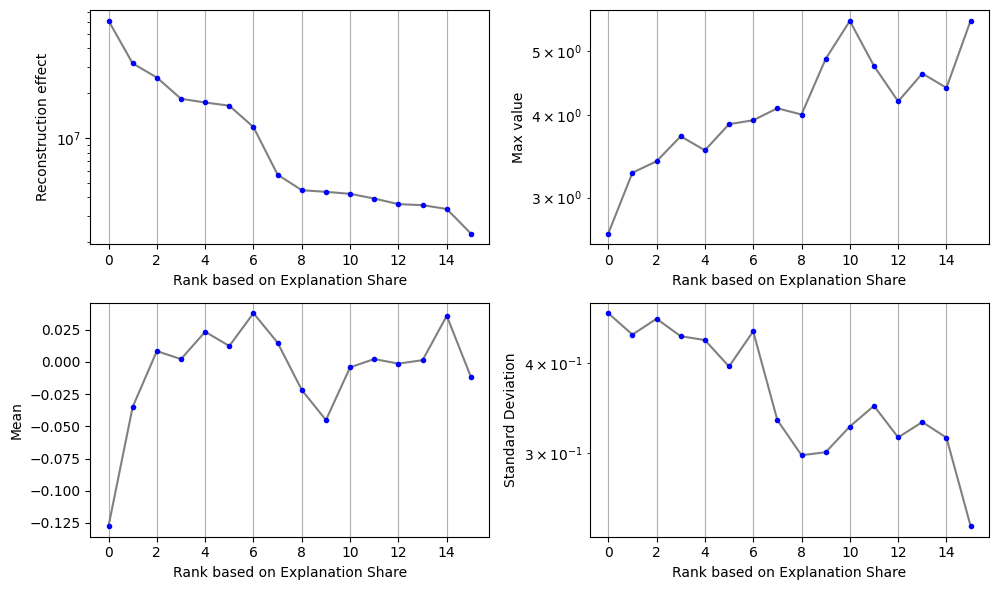

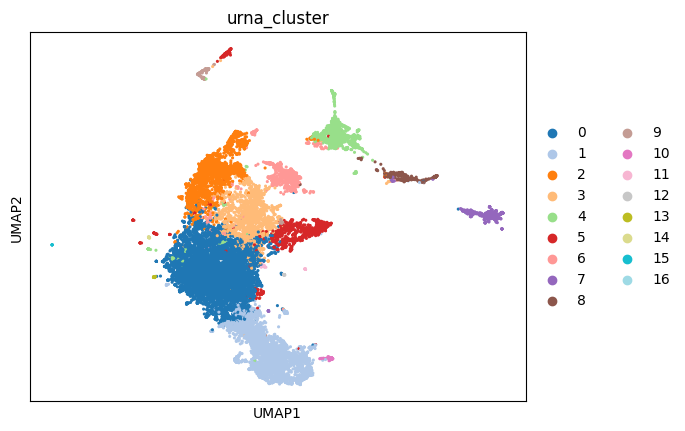

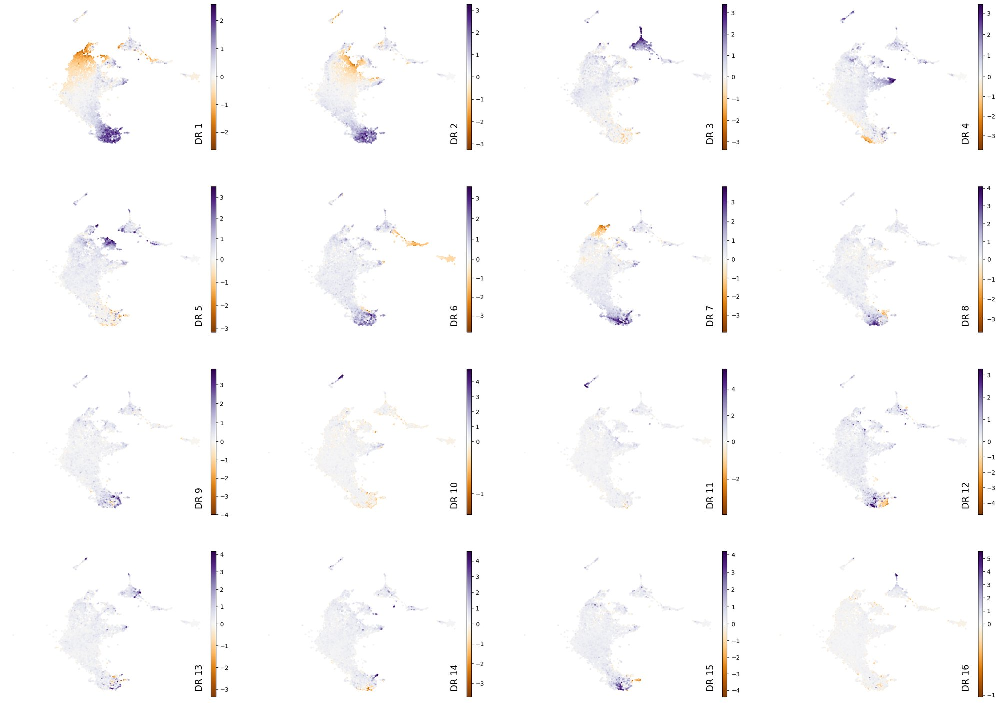

In [13]:
sc.pl.umap(embed,color='urna_cluster',palette='tab20',s=20)
drvi.utils.pl.plot_latent_dims_in_umap(embed,cmap='PuOr',vcenter=0,s=20)

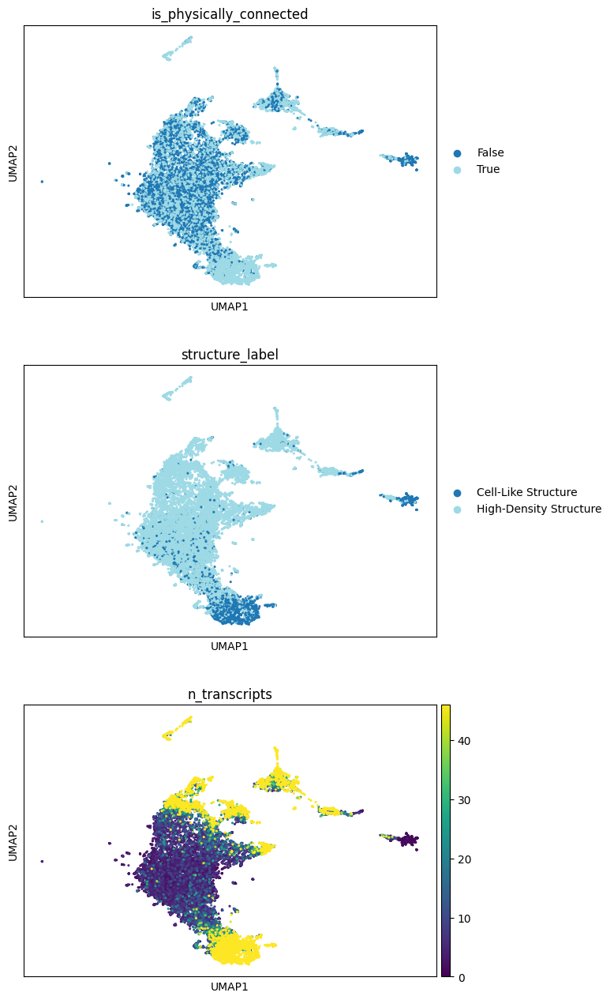

In [14]:
sc.pl.umap(embed,color=['is_physically_connected','structure_label','n_transcripts'],palette='tab20',s=20,vmax='p80',ncols=1)

In [15]:
# 1. Store the raw latent embedding matrix (X_drvi)
sdata["structure_table"].obsm["X_drvi"] = embed.X
sdata["structure_table"].obsm["X_umap_drvi"] = embed.obsm["X_umap"]
sdata["structure_table"].obs["urna_cluster"] = embed.obs["urna_cluster"]
sdata['structure_table'].uns['drvi_dr_stats'] = embed.var.copy()

## Find DEG

It seems you use rank_genes_groups on the raw count data. Please logarithmize your data before calling rank_genes_groups.


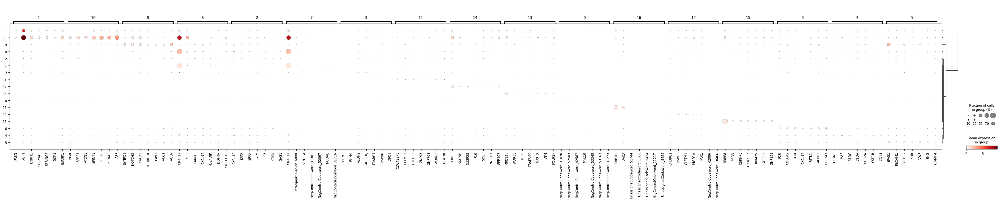

{'0': ['NegControlCodeword_31870', 'NegControlCodeword_52583', 'NegControlCodeword_42567', 'MYL10', 'NegControlCodeword_53348', 'NegControlCodeword_53163', 'NegControlCodeword_31273', 'NegControlCodeword_20469', 'UnassignedCodeword_7073', 'NegControlCodeword_42672'], '1': ['FASN', 'XBP1', 'ERRFI1', 'SLC29A2', 'SERINC2', 'SDK2', 'IER3IP1', 'SHROOM3', 'ZNF703', 'THSD4'], '10': ['INSR', 'SFRP1', 'VTCN1', 'SPINT1', 'CCL28', 'PROM1', 'APP', 'NFIB', 'ANPEP', 'EFNA1'], '11': ['CDC42EP5', 'OLFML1', 'GTPBP3', 'ZNF93', 'ZNF708', 'WDR83', 'PDGFRB', 'SF3B6', 'CYB5A', 'NABP2'], '12': ['CHURC1', 'HSPE1', 'CLPTM1', 'HIGD1A', 'FAR1', 'NegControlCodeword_42086', 'NegControlCodeword_10466', 'NegControlCodeword_52826', 'NegControlCodeword_52827', 'UnassignedCodeword_50755'], '13': ['MED13L', 'WDR33', 'SNCG', 'TRAF3IP2', 'MPZL2', 'AK4', 'POLR2F', 'PDE5A', 'BLTP2', 'CDC42EP4'], '14': ['CIRBP', 'STAT5B', 'DUSP28', 'F10', 'SOBP', 'ZNF287', 'GPR107', 'MFSD8', 'NNMT', 'OCEL1'], '15': ['RBBP8', 'PSG3', 'CSRNP3'

In [16]:
embed_filt=embed
struc2urna=dict(zip(embed_filt.obs.index,embed_filt.obs['urna_cluster']))
adata.obs['urna_cluster']=adata.obs.index.map(struc2urna)
#sc.pp.normalize_total(adata)
#sc.pp.log1p(adata)
##### 
adata.obs['urna_cluster']=adata.obs['urna_cluster'].astype('category')
sc.tl.dendrogram(adata,groupby='urna_cluster')
sc.tl.rank_genes_groups(adata,groupby='urna_cluster')
sc.pl.rank_genes_groups_dotplot(adata,groupby='urna_cluster',n_genes=7)
marker_dict = {}
for cluster in sorted(adata.obs["urna_cluster"].unique()):
    df = sc.get.rank_genes_groups_df(adata, group=str(cluster))
    # Get top 3 names
    marker_dict[str(cluster)] = df["names"].head(10).tolist()

# Prints a single-line collapsed dictionary perfect for copy-pasting
print(marker_dict)


In [17]:
dict_structure_anno = {
    "0": "Technical Background Noise",
    "1": "Lipogenic Luminal Tumor Cells",
    "2": "Inflammatory CAFs / iCAFs",
    "3": "Mature Adipocytes / Breast Fat",
    "4": "Tumor-Associated Macrophages / TAMs",
    "5": "Vascular Endothelial Cells",
    "6": "Desmoplastic Myofibroblasts / myCAFs",
    "7": "Technical Background / Intergenic Artifacts",
    "8": "Basement Membrane / Fibrovascular Interface",
    "9": "Myoepithelial Cells / Mural Stroma",
    "10": "Luminal Progenitor / Immune-Evasive Tumor Cells",
    "11": "Perivascular Pericytes / PDGFRB+ Stroma",
    "12": "Hypoxic / Necrotic Core Artifacts",
    "13": "Invasive / Metastatic-State Tumor Subclone",
    "14": "Differentiated Luminal Epithelium",
    "15": "Proliferating / DNA-Repair Active Tumor Cells",
    "16": "Technical Background / Unassigned Codewords",
}

# Note: Replace 'leiden' with your actual cluster column name if it differs
embed_filt.obs["structure_annotation"] = (
    embed_filt.obs["urna_cluster"].astype(str).map(dict_structure_anno)
)
adata.obs["structure_annotation"] = (
    adata.obs["urna_cluster"].astype(str).map(dict_structure_anno)
)

sdata["structure_table"].obs['structure_annotation']=sdata["structure_table"].obs["urna_cluster"].astype(str).map(dict_structure_anno)

In [21]:
sdata.write(data_dir / "data_with_source_score_optimized_params_annotated_real.zarr",overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/atera_hsbreast/data_with_source_score_
         optimized_params_annotated_real.zarr). Please see the documentation of `is_self_contained()` to understand
         the implications of working with SpatialData objects that are not self-contained.                         
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/atera_hsbreast/data_with_source_score_
         optimized_params.zarr the new file path:                                                                  
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/

# Visualize 

In [7]:
sdata=sd.read_zarr(data_dir / "data_with_source_score_optimized_params_annotated_real.zarr")

It seems you use rank_genes_groups on the raw count data. Please logarithmize your data before calling rank_genes_groups.


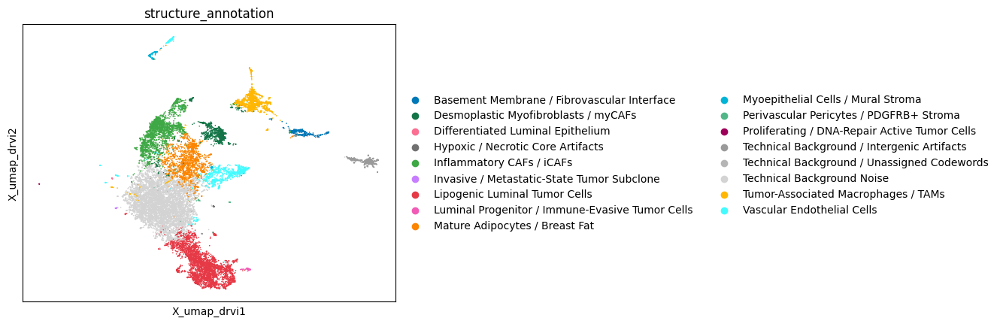

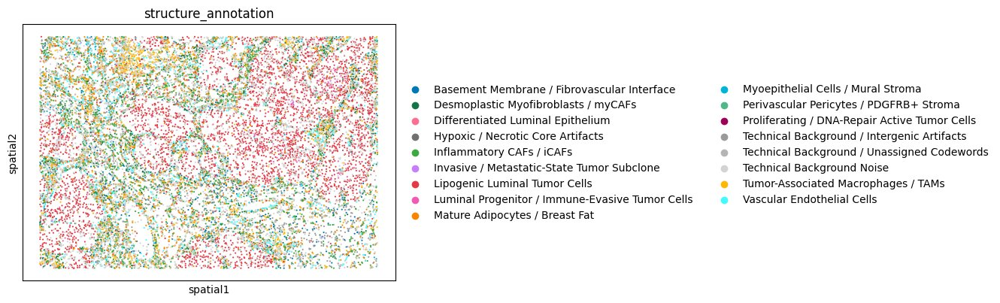

In [10]:
adata=sdata['structure_table']

import matplotlib

# 1. Compute the dendrogram lineage using your DRVI latent representation
adata.obs['structure_annotation']=adata.obs['structure_annotation'].astype('category')

sc.tl.dendrogram(adata, groupby="structure_annotation", use_rep="X_drvi")
sc.tl.rank_genes_groups(adata, groupby="structure_annotation", method="wilcoxon")

# 3. Configure global canvas sizes and smaller text margins for your long labels
plt.rcParams.update({"font.size": 9,"xtick.labelsize": 8, "ytick.labelsize": 8,})


# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# 4. Generate the dotplot (Setting show=False keeps the figure open in memory)
dotplot_obj = sc.pl.rank_genes_groups_dotplot(
adata, groupby="structure_annotation", n_genes=2, cmap="Blues", show=False)

# 5. Save the figure directly to your designated saving path
plt.savefig(os.path.join(saving_path, "latent_structure_dendrogram_dotplot_2.pdf"),
    bbox_inches="tight",dpi=300)

# Close the figure and reset styles to defaults
plt.close()
plt.rcParams.update(plt.rcParamsDefault)

import os
import matplotlib.pyplot as plt
import scanpy as sc

# Clear out any stale color configurations
if "structure_annotation_colors" in sdata["structure_table"].uns:
    del sdata["structure_table"].uns["structure_annotation_colors"]

# 1. Enforce category type so order is explicitly alphanumeric
sdata["structure_table"].obs["structure_annotation"] = (
    sdata["structure_table"].obs["structure_annotation"].astype(str).astype("category")
)

# 2. Map annotations to custom color palettes (matching your exact category names)
tumor_stroma_colors = {
    "Technical Background Noise": "#D3D3D3",  # Light Gray
    "Lipogenic Luminal Tumor Cells": "#E63946",  # Tomato Red
    "Inflammatory CAFs / iCAFs": "#3ea845",  # Muted Teal-Green
    "Mature Adipocytes / Breast Fat": "#FB8500",  # Bright Orange
    "Tumor-Associated Macrophages / TAMs": "#FFB703",  # Warm Yellow / Gold
    "Vascular Endothelial Cells": "#43FBFF",  # Bright Cyan
    "Desmoplastic Myofibroblasts / myCAFs": "#137547",  # Deep Forest Green
    "Technical Background / Intergenic Artifacts": "#9A9A9A",  # Medium Slate Gray
    "Basement Membrane / Fibrovascular Interface": "#0077B6",  # Deep Steel Blue
    "Myoepithelial Cells / Mural Stroma": "#00B4D8",  # Mid-Tone Blue
    "Luminal Progenitor / Immune-Evasive Tumor Cells": "#F15BB5",  # Hot Pink
    "Perivascular Pericytes / PDGFRB+ Stroma": "#52B788",  # Minty Green
    "Hypoxic / Necrotic Core Artifacts": "#707070",  # Dark Charcoal Gray
    "Invasive / Metastatic-State Tumor Subclone": "#C77DFF",  # Royal Purple
    "Differentiated Luminal Epithelium": "#FB6F92",  # Soft Coral Pink
    "Proliferating / DNA-Repair Active Tumor Cells": "#9E0059",  # Deep Burgundy
    "Technical Background / Unassigned Codewords": "#B5B5B5",  # Soft Gray
}

# Extract unique labels sorted alphabetically (matching Scanpy's categorical index)
ordered_categories = sdata["structure_table"].obs["structure_annotation"].cat.categories

# Generate the color list aligned to the alphanumeric categorical sort order
structure_colors = [tumor_stroma_colors[cat] for cat in ordered_categories]

# Inject directly into your spatial data table
sdata["structure_table"].uns["structure_annotation_colors"] = structure_colors

# 3. Generate and Save plots
# Plot UMAP

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

sc.pl.embedding(sdata["structure_table"],color="structure_annotation",basis="X_umap_drvi",show=False,)
plt.savefig(os.path.join(saving_path, "umap_structure_annotations.pdf"), bbox_inches="tight")
plt.show()
plt.close()

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
# Plot Spatial Map
sc.pl.spatial(sdata["structure_table"],color="structure_annotation",spot_size=10,show=False,)
plt.savefig(os.path.join(saving_path, "spatial_structure_annotations.pdf"),bbox_inches="tight")

plt.show()
plt.close()

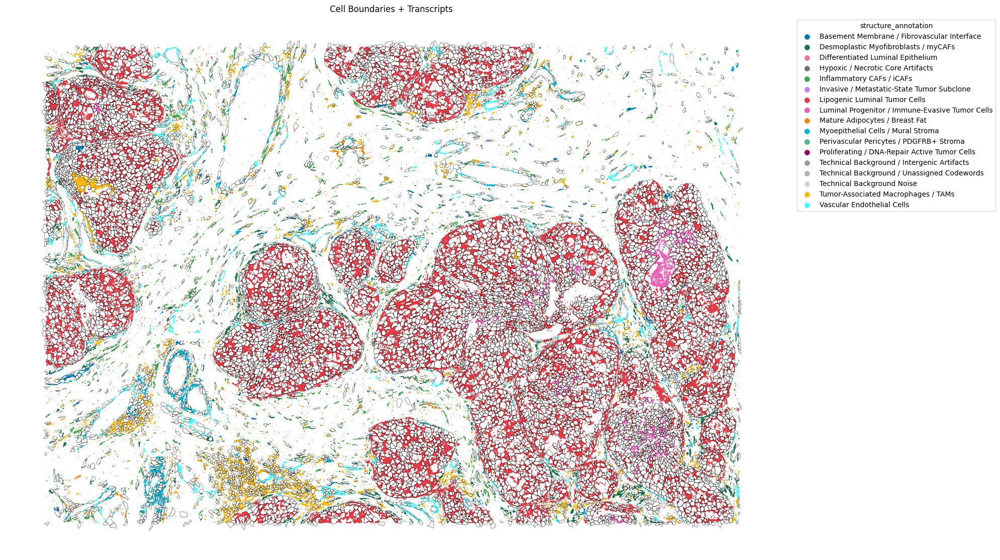

In [67]:
import matplotlib.colors as mcolors

# Extract the exact colors Scanpy used
scanpy_colors = sdata["structure_table"].uns["structure_annotation_colors"]
sdata['structure_table'].obs['structure_annotation']=sdata['structure_table'].obs['structure_annotation'].astype(str)
scanpy_cmap = mcolors.ListedColormap(scanpy_colors)

fig = pl.spatial_transcripts(sdata,color_key="structure_annotation",
colormap=scanpy_cmap,scatter_size=0.2,use_roi=False,roi=(4500,5000,2200,2700),
    figsize=(20,20),boundary_linewidth=0.8,alpha=1, 
    rasterize=True,missing_val_sentinel=-1)
plt.savefig(os.path.join(saving_path,'spatial_transcripts_structure_annotation_full.pdf'))
plt.show()


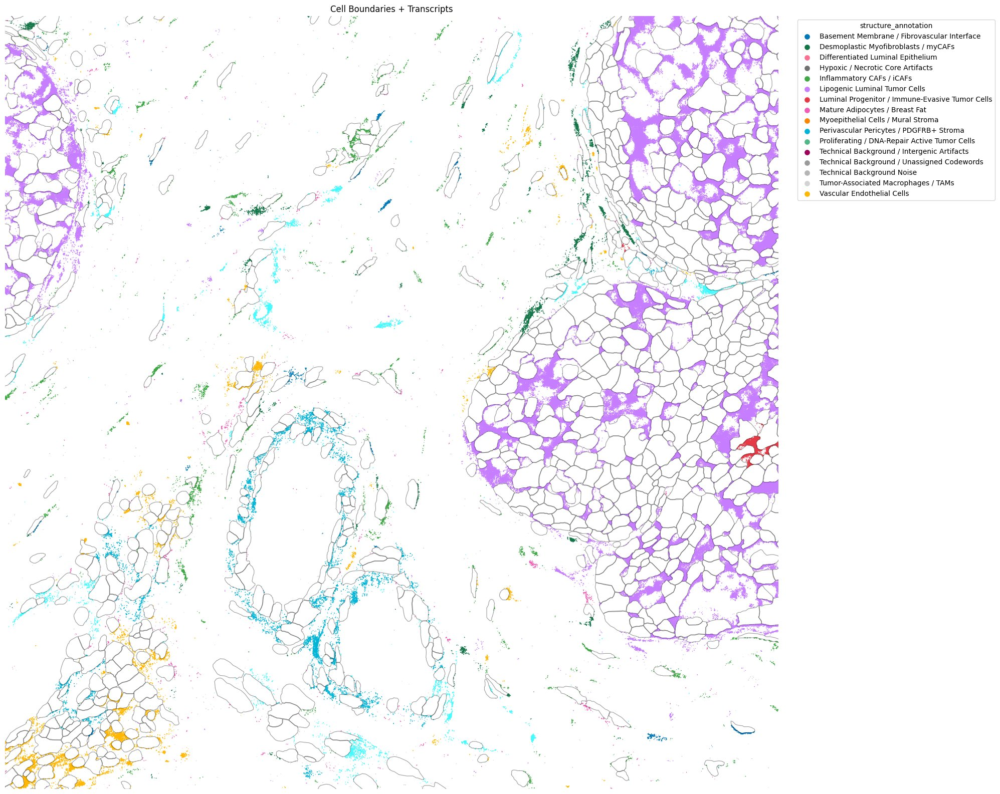

In [66]:
fig = pl.spatial_transcripts(sdata,color_key="structure_annotation",
colormap=scanpy_cmap,scatter_size=0.5,use_roi=True,roi=(4500,5000,2200,2700),
    figsize=(20,20),boundary_linewidth=0.8,alpha=1, 
    rasterize=True,missing_val_sentinel=-1)
plt.savefig(os.path.join(saving_path,'spatial_transcripts_structure_annotation_roi.pdf'))
plt.show()

In [60]:
sdata['structure_table'].obs['is_physically_connected']=sdata['structure_table'].obs['is_physically_connected'].astype(str)
colors_structures=["#e52974","#91bb4f"]
scanpy_cmap = mcolors.ListedColormap(colors_structures)
fig=pl.spatial_transcripts(
    sdata,
    color_key="is_physically_connected",
    scatter_size=1.2,use_roi=True, roi=(4500,5000,2200,2700),figsize=(20,20),boundary_linewidth=0.8,
    colormap=scanpy_cmap,
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1,continuous_colormap='winter')
plt.savefig(os.path.join(saving_path,'spatial_transcripts_physically_connected_roi.pdf'))
plt.show()

In [61]:
colors_structures=["#e52974","#91bb4f"]
scanpy_cmap = mcolors.ListedColormap(colors_structures)
fig=pl.spatial_transcripts(
    sdata,
    color_key="is_physically_connected",  colormap=scanpy_cmap,
    scatter_size=0.4,use_roi=False, roi=(4900, 5700, 2100, 2800),figsize=(20,20),boundary_linewidth=0.8,
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1,continuous_colormap='winter')
plt.savefig(os.path.join(saving_path,'spatial_transcripts_physically_connected_all.pdf'))
plt.show()

In [69]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize
from shapely.geometry import box
from shapely.affinity import affine_transform

def spatial_transcripts(
    sdata,
    gene_key: str = "gene",
    gene_list: list[str] | None = None,
    color_key: str = "point_source_cellular",
    shapes_key: str = "cell_boundaries",
    table_key: str = "table",
    structure_table_key: str = "structure_table",
    source_table_key: str = "source_score",
    colormap: str = "30colors",
    continuous_colormap: str = "viridis",
    boundary_linewidth: float = 0.5,
    boundary_zorder: int = 4,
    scatter_size: float = 1.0,
    alpha: float = 0.8,
    use_roi: bool = False,
    roi: tuple[float, float, float, float] = (0, 20000, 0, 20000),
    figsize: tuple[float, float] = (8, 8),
    title: str = "Cell Boundaries + Transcripts",
    vmin: float | None = None,
    vmax: float | None = None,
    rasterize: bool = True,
    missing_val_sentinel: int | str | float = -1,
) -> tuple[plt.Figure, plt.Axes]:
    
    target_col = "point_source" if color_key == "point_source_cellular" else color_key
    required_cols = ["x", "y", gene_key, "overlaps_cell"]

    transcripts_lazy = sdata.points["transcripts"]
    is_direct_column = target_col in transcripts_lazy.columns

    if is_direct_column:
        required_cols.append(target_col)

    # Base configuration mapping
    search_configs = [
        (source_table_key, None),
        (structure_table_key, "structure_id"),
        (table_key, "cell_id"),
    ]

    # Dynamically include ID columns if they exist
    for t_key, trans_id_col in search_configs:
        if t_key in sdata.tables and trans_id_col is not None:
            required_cols.append(trans_id_col)

    required_cols = list(set(required_cols))
    available_cols = [c for c in required_cols if c in transcripts_lazy.columns]
    transcripts_lazy_subset = transcripts_lazy[available_cols]

    if gene_list is not None:
        transcripts_lazy_subset = transcripts_lazy_subset[transcripts_lazy_subset[gene_key].isin(gene_list)]

    trans_ad = transcripts_lazy_subset.compute().copy()

    if color_key not in trans_ad.columns:
        trans_ad[color_key] = np.nan

    # --- MODIFIED: COMBINED MAPPING STRATEGY ---
    # Instead of breaking early at the first matching table, we look up mapping maps
    # across both structure_table AND table_key, combining them seamlessly.
    if color_key != "point_source_cellular" and not is_direct_column:
        combined_series = pd.Series(index=trans_ad.index, dtype=object)
        
        # 1. Look up annotations from the Structure Table via structure_id
        if structure_table_key in sdata.tables and "structure_id" in trans_ad.columns:
            struct_obs = sdata[structure_table_key].obs
            if target_col in struct_obs.columns:
                if "instance_id" in struct_obs.columns:
                    map_source = struct_obs.set_index("instance_id")[target_col]
                elif "cell_id" in struct_obs.columns:
                    map_source = struct_obs.set_index("cell_id")[target_col]
                else:
                    map_source = struct_obs[target_col]
                map_source.index = map_source.index.astype(str)
                
                # Assign structure-based parent annotations
                struct_mapped = trans_ad["structure_id"].astype(str).map(map_source)
                combined_series = combined_series.fillna(struct_mapped)

        # 2. Look up annotations from the Cellular Table via cell_id
        if table_key in sdata.tables and "cell_id" in trans_ad.columns:
            cell_obs = sdata[table_key].obs
            # Fallback: if user looks for predicted_parent_cell_type but main table has 'cell_type'
            cell_target_col = 'cell_type' if (target_col == 'predicted_parent_cell_type' and 'cell_type' in cell_obs.columns) else target_col
            
            if cell_target_col in cell_obs.columns:
                if "cell_id" in cell_obs.columns:
                    map_source = cell_obs.set_index("cell_id")[cell_target_col]
                else:
                    map_source = cell_obs[cell_target_col]
                map_source.index = map_source.index.astype(str)
                
                # Assign intracellular annotations where structure didn't cover
                cell_mapped = trans_ad["cell_id"].astype(str).map(map_source)
                combined_series = combined_series.fillna(cell_mapped)

        trans_ad[color_key] = combined_series

    # Legacy handling for standard point_source_cellular tracking
    elif color_key == "point_source_cellular":
        if target_col not in trans_ad.columns:
            trans_ad[target_col] = np.nan
            for t_key, trans_id_col in search_configs:
                if t_key in sdata.tables and target_col in sdata[t_key].obs.columns:
                    table_obs = sdata[t_key].obs
                    if trans_id_col is None:
                        table_series = table_obs[target_col]
                        table_series.index = table_series.index.astype(str)
                        trans_ad[target_col] = trans_ad.index.astype(str).map(table_series)
                    else:
                        if "instance_id" in table_obs.columns:
                            map_source = table_obs.set_index("instance_id")[target_col]
                        elif "cell_id" in table_obs.columns:
                            map_source = table_obs.set_index("cell_id")[target_col]
                        else:
                            map_source = table_obs[target_col]
                        map_source.index = map_source.index.astype(str)
                        trans_ad[target_col] = trans_ad[trans_id_col].astype(str).map(map_source)
                    if not trans_ad[target_col].isna().all():
                        break
        is_intra_bool = trans_ad["overlaps_cell"].astype(str).str.lower() == "true"
        trans_ad["point_source_cellular"] = np.where(is_intra_bool, "cellular transcripts", trans_ad[target_col].astype(str))
        trans_ad.loc[trans_ad[target_col].isna(), "point_source_cellular"] = np.nan

    # Standard clean up of missing markers
    trans_ad[color_key] = trans_ad[color_key].replace("nan", np.nan)
    if missing_val_sentinel is not None:
        sentinel_str = str(missing_val_sentinel)
        trans_ad[color_key] = trans_ad[color_key].replace([missing_val_sentinel, sentinel_str], np.nan)

    is_nan_mask = trans_ad[color_key].isna()
    trans_ad[color_key] = trans_ad[color_key].fillna("Unmapped")
    is_bg = trans_ad[color_key] == "Unmapped"
    trans_df = trans_ad.copy()

    # Geometry generation & transformation Handling
    cb = sdata[shapes_key]
    df = cb.copy()
    try:
        from spatialdata import get_transformation
        trans = get_transformation(cb)
        if hasattr(trans, "matrix") and trans.matrix is not None:
            m = trans.matrix
            params = [m[0, 0], m[0, 1], m[1, 0], m[1, 1], m[0, 2], m[1, 2]]
            df["geometry"] = df["geometry"].apply(lambda g: affine_transform(g, params))
    except Exception:
        pass
    gdf = gpd.GeoDataFrame(df, geometry="geometry")

    if use_roi:
        xmin, xmax, ymin, ymax = roi
        roi_poly = box(xmin, ymin, xmax, ymax)
        gdf = gdf[gdf.geometry.intersects(roi_poly)]
        mask = (trans_df["x"] >= xmin) & (trans_df["x"] <= xmax) & (trans_df["y"] >= ymin) & (trans_df["y"] <= ymax)
        trans_df = trans_df[mask]
        is_bg = is_bg[mask]
        is_nan_mask = is_nan_mask[mask]

    fg_df = trans_df[~is_bg].copy()
    unmapped_df = trans_df[is_bg & ~is_nan_mask].copy()

    cmap, norm, is_numeric, cats = None, None, False, None

    if not fg_df.empty:
        numeric_check = pd.to_numeric(fg_df[color_key], errors="coerce")
        if not numeric_check.isna().all() and pd.api.types.is_numeric_dtype(numeric_check):
            is_numeric = True
            vals = fg_df[color_key].astype(float)
            try:
                cmap = plt.get_cmap(colormap)
            except ValueError:
                cmap = plt.get_cmap(continuous_colormap)
            plot_vmin = vmin if vmin is not None else vals.min()
            plot_vmax = vmax if vmax is not None else (1.0 if vals.max() <= 1.0 else vals.max())
            norm = Normalize(vmin=plot_vmin, vmax=plot_vmax)
        else:
            is_numeric = False

            if color_key == "point_source_cellular":
                defined_order = ["cellular transcripts", "cell_like_source", "other", "high_density_source"]
                present_cats = [c for c in defined_order if c in fg_df[color_key].unique()]
                extra_cats = [c for c in fg_df[color_key].unique() if c not in defined_order]
                final_order = present_cats + extra_cats
                fg_df[color_key] = pd.Categorical(fg_df[color_key], categories=final_order, ordered=True)
                cats = fg_df[color_key].cat.categories
            else:
                # --- MODIFIED: GLOBAL CATEGORIES FIX ---
                # Pull global categories from the main table uns colors matching structure to avoid color-shifts in ROI
                if table_key in sdata.tables and "cell_type" in sdata[table_key].obs.columns:
                    global_order = sorted(sdata[table_key].obs["cell_type"].unique().tolist())
                    fg_df[color_key] = pd.Categorical(fg_df[color_key], categories=global_order)
                else:
                    fg_df[color_key] = fg_df[color_key].astype("category")
                
                cats = fg_df[color_key].cat.categories

            if isinstance(colormap, ListedColormap):
                cmap = colormap
            else:
                try:
                    from troutpy.pl import get_palette
                    pal = get_palette(colormap, len(cats))
                    cmap = ListedColormap(pal)
                except (ValueError, ImportError):
                    cmap = plt.get_cmap(colormap if colormap in plt.colormaps() else "tab20", len(cats))

    fig, ax = plt.subplots(figsize=figsize)
    gdf.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=boundary_linewidth, alpha=0.4, zorder=boundary_zorder)

    if not unmapped_df.empty:
        ax.scatter(unmapped_df["x"], unmapped_df["y"], c="#A0A0A0", s=scatter_size, edgecolor="none", alpha=alpha, zorder=2, rasterized=rasterize)

    if not fg_df.empty:
        c_vals = fg_df[color_key] if is_numeric else fg_df[color_key].cat.codes
        scatter = ax.scatter(
            fg_df["x"],
            fg_df["y"],
            c=c_vals,
            cmap=cmap,
            norm=norm if is_numeric else None,
            s=scatter_size * 1.5,
            edgecolor="none",
            alpha=1.0,
            zorder=3,
            rasterized=rasterize,
        )
        if is_numeric:
            fig.colorbar(scatter, ax=ax, label=color_key, fraction=0.046, pad=0.04)
        else:
            # Only display categories actually present in the ROI inside the legend
            visible_cats = fg_df[color_key].dropna().unique()
            for idx, cat in enumerate(cats):
                if cat in visible_cats:
                    ax.scatter([], [], color=cmap(idx), label=str(cat), s=20)
            ax.legend(title=color_key, markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")

    ax.set_aspect("equal")
    ax.set_title(title)
    if use_roi:
        ax.set_xlim(roi[0], roi[1])
        ax.set_ylim(roi[2], roi[3])
    ax.axis("off")
    plt.tight_layout()

    return fig, ax


#traverse_adata.write(os.path.join(data_dir,"drvi_msbrain_traverse_adata.h5ad"))
#traverse_adata = sc.read(os.path.join(data_dir,"drvi_msbrain_traverse_adata.h5ad"))

# Vesicle ORA analysis

In [31]:
#str2urna=dict(zip(embed.obs.index,embed.obs['urna_cluster']))
#sdata['structure_table'].obs['urna_cluster']=sdata['structure_table'].obs.index.map(str2urna)

results_df = calculate_ev_ora(
    sdata=sdata,
    vesiclepedia_path="/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ref_databases/VESICLEPEDIA_PROTEIN_MRNA_DETAILS_5.1.txt",
    table_key="structure_table",
    cluster_key="structure_annotation",
    species="Homo sapiens",
    case_normalization="upper",
    alpha_marker=0.05,  # Adjusted p-val threshold for cluster markers
    min_logfc=0.1       # Select upregulated genes only
)

# Display your results dataframe
print(results_df)



Loading Vesiclepedia and filtering for species: Homo sapiens...
Loaded 489 high-confidence database genes.
Dataset Background Universe (M): 24501 unique genes.
Intersected EV Target Genes (n): 365 genes mapped to dataset features.
Calculating marker profiles using Wilcoxon grouping by 'structure_annotation'...


It seems you use rank_genes_groups on the raw count data. Please logarithmize your data before calling rank_genes_groups.


⚠️ Cluster 'Technical Background Noise' has 0 significant upregulated markers. Skipping.
⚠️ Cluster 'Mature Adipocytes / Breast Fat' has 0 significant upregulated markers. Skipping.
⚠️ Cluster 'Proliferating / DNA-Repair Active Tumor Cells' has 0 significant upregulated markers. Skipping.
⚠️ Cluster 'Hypoxic / Necrotic Core Artifacts' has 0 significant upregulated markers. Skipping.
⚠️ Cluster 'Technical Background / Unassigned Codewords' has 0 significant upregulated markers. Skipping.
⚠️ Cluster 'Perivascular Pericytes / PDGFRB+ Stroma' has 0 significant upregulated markers. Skipping.
⚠️ Cluster 'Invasive / Metastatic-State Tumor Subclone' has 0 significant upregulated markers. Skipping.
⚠️ Cluster 'Differentiated Luminal Epithelium' has 0 significant upregulated markers. Skipping.

Enrichment analysis complete.
                                           cluster  cluster_marker_count  \
0                    Lipogenic Luminal Tumor Cells                  6528   
1  Luminal Progenitor 

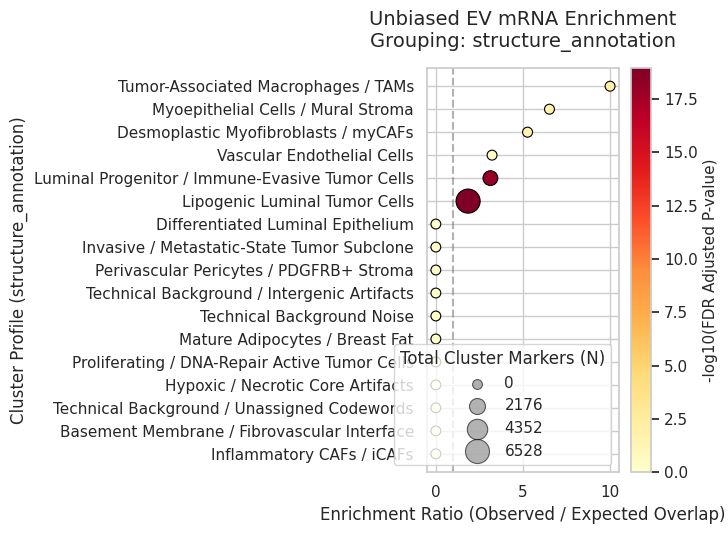

In [32]:
# Run with standard settings (Yellow-Orange-Red)
plot_ev_enrichment(
    sdata=sdata,
    results_df=results_df,
    table_key="structure_table",
    cluster_key="structure_annotation",
    cmap="YlOrRd",saving_path=os.path.join(saving_path,'ora_urna_structures_vesiclepedia.pdf'))


Loading Vesiclepedia and filtering for species: Homo sapiens...
Loaded 489 high-confidence database genes.
Dataset Background Universe (M): 17996 unique genes.
Intersected EV Target Genes (n): 365 genes mapped to dataset features.
Calculating marker profiles using Wilcoxon grouping by 'cell_type'...


It seems you use rank_genes_groups on the raw count data. Please logarithmize your data before calling rank_genes_groups.


⚠️ Cluster 'Angiogenic Endothelial Cells' has 0 significant upregulated markers. Skipping.

Enrichment analysis complete.
                                  cluster  cluster_marker_count  \
0           Tumor cells (Secretory/XBP1+)                  2575   
1   Tumor cells (Luminal Progenitor-like)                  4494   
2    Tumor cells (Luminal Differentiated)                  5161   
3                 Tumor cells (Luminal A)                  6071   
4     Tumor cells (Cycling/Proliferating)                  6364   
5       Tumor cells (Luminal TFF1/3 High)                  3782   
6               Tumor cells (Luminal HR+)                  8693   
7           Tumor cells (MDM2+ Amplified)                  1844   
8     Tumor cells (Basal-like/Progenitor)                   490   
9    Cancer-Associated Fibroblasts (CAFs)                   558   
10                         Plasma B Cells                    60   
11           Mural Cells (Pericytes/SMCs)                   562   
12     

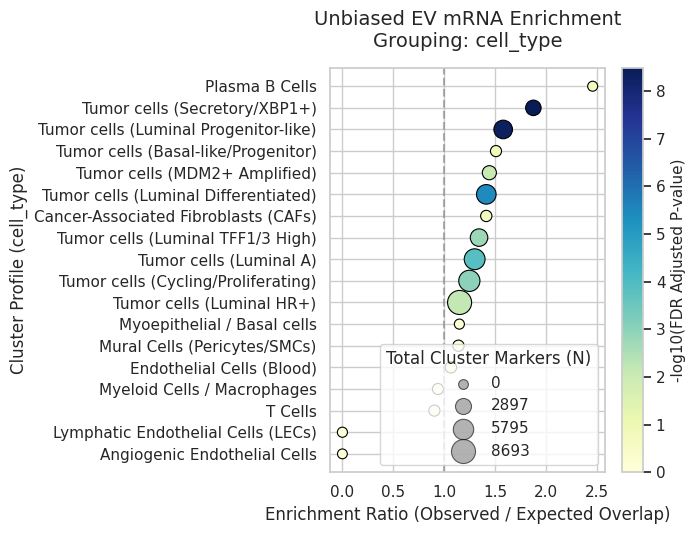

In [40]:
#str2urna=dict(zip(embed.obs.index,embed.obs['urna_cluster']))
#sdata['structure_table'].obs['urna_cluster']=sdata['structure_table'].obs.index.map(str2urna)

results_df = calculate_ev_ora(
    sdata=sdata,
    vesiclepedia_path="/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ref_databases/VESICLEPEDIA_PROTEIN_MRNA_DETAILS_5.1.txt",
    table_key="table",
    cluster_key="cell_type",
    species="Homo sapiens",
    case_normalization="upper",
    alpha_marker=0.05,  # Adjusted p-val threshold for cluster markers
    min_logfc=0.1       # Select upregulated genes only
)

# Display your results dataframe
print(results_df)

# Run with standard settings (Yellow-Orange-Red)
plot_ev_enrichment(
    sdata=sdata,
    results_df=results_df,
    table_key="table",
    cluster_key="cell_type",
    cmap="YlGnBu",saving_path=os.path.join(saving_path,'ora_cell_type_vesiclepedia.pdf'))

In [36]:
sdata['table'].obs

,cell_id,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,...,leiden,area,perimeter,solidity,major_axis_length,equivalent_diameter,circularity,protrusion_length,morphological_complexity,urna_source_score
9058,amibijbe-1,5446,0,0,0,0,0,5446,88.996444,53.235316,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,165.264610
9059,amichbkd-1,1671,0,1,1,0,0,1673,39.779740,36.980258,...,0,1971.0,175.823376,0.970458,65.252980,50.095460,0.801204,7.578760,0.029542,42.618153
9060,amicofjp-1,5102,0,1,0,1,0,5104,109.676491,57.479692,...,0,881.0,127.982756,0.935244,52.964968,33.492149,0.675901,9.736410,0.064756,260.777633
9061,amidjceb-1,6247,0,2,2,1,0,6252,110.985926,86.919409,...,0,2429.0,192.894444,0.973157,59.565944,55.612039,0.820348,1.976953,0.026843,162.853567
9062,amiebcik-1,2540,1,2,0,0,0,2543,48.268493,39.463669,...,0,2458.0,190.409163,0.975784,67.283604,55.943032,0.851954,5.670286,0.024216,33.559770
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
169912,oiodeajm-1,432,0,0,0,0,0,432,54.860822,11.423694,...,5,555.0,89.840620,0.965217,33.646884,26.582851,0.864087,3.532017,0.034783,3.078348
169928,oiohcbpd-1,574,0,0,1,0,0,575,28.310893,10.249717,...,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.880372
169939,oioklnjp-1,103,0,0,0,0,0,103,8.353294,8.353294,...,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.784142
170046,ojbajoec-1,414,0,0,0,0,0,414,8.082376,8.082376,...,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.353326


# Annotation include

In [38]:
sdata_annotated=sd.read_zarr(data_dir / "data_annotated.zarr")

In [39]:
id2anno=dict(zip(sdata_annotated['table'].obs['cell_id'],sdata_annotated['table'].obs['cell_type']))
sdata['table'].obs['cell_type']=sdata['table'].obs['cell_id'].map(id2anno)#,sdata_annotated.obs['cell_type']))
sdata["table"].uns["cell_type_colors"]=sdata_annotated["table"].uns["cell_type_colors"]

In [83]:
id2ct=dict(zip(sdata['table'].obs.index,sdata['table'].obs['cell_type']))
sdata['structure_table'].obs['predicted_parent_cell_type']=sdata['structure_table'].obs['predicted_parent'].map(id2ct)

import matplotlib.colors as mcolors

# 1. Grab your original global scanpy colors
scanpy_colors = sdata["table"].uns["cell_type_colors"]
scanpy_cmap = mcolors.ListedColormap(scanpy_colors)

# 2. Call your newly updated function
# It will now combine the tables and map colors flawlessly!
fig, ax = spatial_transcripts(
    sdata,
    color_key="predicted_parent_cell_type",  
    colormap=scanpy_cmap,                    # Pass the standard ListedColormap directly
    scatter_size=0.4,
    use_roi=False, 
    roi=(4000, 4800, 1000, 1900),
    figsize=(30, 30),
    boundary_linewidth=0.7,
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1
)
plt.savefig(os.path.join(saving_path, 'spatial_combined_cell_type_annotation_full.pdf'))

In [81]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize, TwoSlopeNorm
import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import box
from shapely.affinity import affine_transform

def spatial_transcripts_structures(
    sdata, 
    color_key: str = "leiden",             
    gene_list: str | list[str] | None = None, 
    gene_key: str = "gene",                 
    use_roi: bool = False,
    roi: tuple[float, float, float, float] | None = None, 
    padding: float = 0,           
    point_size: float = 0.1, 
    fig_bg_color: str = 'white', 
    ambient_color: str = 'lightgrey', 
    palette: str | None = None,            
    shapes_key: str = "cell_boundaries",
    boundary_linewidth: float = 0.5,
    boundary_zorder: int = 4,
    axis_numbers: bool = False,
    table_key: str = "table",                   # Main cell table key
    structure_table_key: str = "structure_table" # Structure table key
):
    # --------------------------------------------------------------------------
    # 1. Resolve which table holds our metadata/DR keys and find the join key
    # --------------------------------------------------------------------------
    chosen_table_key = None
    id_column_needed = "structure_id"  # fallback default
    
    # Check structure_table first
    if structure_table_key in sdata.tables:
        st = sdata[structure_table_key]
        if color_key in st.obs.columns or ("drvi_dr_stats" in st.uns and color_key in st.uns["drvi_dr_stats"].get("title", pd.Series()).values):
            chosen_table_key = structure_table_key
            id_column_needed = "structure_id"

    # Check cell table second if not found in the structure table
    if chosen_table_key is None and table_key in sdata.tables:
        ct = sdata[table_key]
        if color_key in ct.obs.columns or ("drvi_dr_stats" in ct.uns and color_key in ct.uns["drvi_dr_stats"].get("title", pd.Series()).values):
            chosen_table_key = table_key
            # Cell tables map via cell_id if present in points, otherwise fallback to structure_id
            id_column_needed = "cell_id" if "cell_id" in sdata.points["transcripts"].columns else "structure_id"

    # Absolute fallback to maintain original structural behavior safely if completely missing
    if chosen_table_key is None:
        chosen_table_key = structure_table_key
        id_column_needed = "structure_id"

    # --------------------------------------------------------------------------
    # 2. Fetch only the strictly required columns dynamically from Dask points
    # --------------------------------------------------------------------------
    required_cols = ['x', 'y', gene_key, id_column_needed]
    # Keep only the tracking identifiers that exist in the underlying point dataframe
    available_cols = [c for c in required_cols if c in sdata.points["transcripts"].columns]
    transcripts_lazy = sdata.points["transcripts"][available_cols]
    
    if gene_list is not None:
        if isinstance(gene_list, str):
            gene_list = [gene_list]
        transcripts_lazy = transcripts_lazy[transcripts_lazy[gene_key].isin(gene_list)]

    all_transcripts = transcripts_lazy.compute()
    all_transcripts.index = all_transcripts.index.astype(int)
    
    if all_transcripts.empty:
        print("No transcripts found matching selection criteria.")
        return None, None

    # --------------------------------------------------------------------------
    # 3. Extract Metadata / DR Expression Matrices
    # --------------------------------------------------------------------------
    active_table = sdata[chosen_table_key]
    table_obs = active_table.obs
    
    is_dr = False
    is_numeric = False
    
    if color_key in table_obs.columns:
        structure_values = table_obs[color_key]
        is_numeric = pd.api.types.is_numeric_dtype(structure_values)
    elif "drvi_dr_stats" in active_table.uns:
        dr_stats = active_table.uns["drvi_dr_stats"]
        if "title" in dr_stats.columns and color_key in dr_stats["title"].values:
            dr_idx = list(dr_stats["title"].values).index(color_key)
            dr_vector = active_table.obsm["X_drvi"][:, dr_idx]
            structure_values = pd.Series(dr_vector, index=table_obs.index)
            is_dr = True
            is_numeric = True
        else:
            raise KeyError(f"'{color_key}' not found in {chosen_table_key}.obs columns or drvi_dr_stats titles.")
    else:
        raise KeyError(f"'{color_key}' not found in {chosen_table_key}.obs and no DR metadata is initialized.")

    # --------------------------------------------------------------------------
    # 4. Perform Transcript-to-Table Index Linkage
    # --------------------------------------------------------------------------
    df_roi = all_transcripts.copy()
    
    # Check if target table index uses prefixed strings (e.g. 'struct_12') or clean numeric indices
    sample_idx = str(table_obs.index[0])
    if sample_idx.startswith('struct_') and id_column_needed == 'structure_id':
        df_roi['lookup_key'] = 'struct_' + df_roi[id_column_needed].astype(int).astype(str)
    else:
        df_roi['lookup_key'] = df_roi[id_column_needed].astype(str)
    
    is_assigned = (df_roi[id_column_needed].astype(int) != -1) & (df_roi['lookup_key'].isin(table_obs.index))
    
    df_roi['color_value'] = np.nan
    df_roi.loc[is_assigned, 'color_value'] = df_roi.loc[is_assigned, 'lookup_key'].map(structure_values)

    # --------------------------------------------------------------------------
    # 5. Handle Viewport / Regions of Interest (ROI)
    # --------------------------------------------------------------------------
    if use_roi and roi is not None:
        x_min, x_max, y_min, y_max = roi
    elif padding > 0:
        x_min, x_max = df_roi['x'].min() + padding, df_roi['x'].max() - padding
        y_min, y_max = df_roi['y'].min() + padding, df_roi['y'].max() - padding
    else:
        x_min, x_max = df_roi['x'].min(), df_roi['x'].max()
        y_min, y_max = df_roi['y'].min(), df_roi['y'].max()

    df_roi = df_roi[df_roi.x.between(x_min, x_max) & df_roi.y.between(y_min, y_max)].copy()
    
    is_assigned_roi = (df_roi[id_column_needed].astype(int) != -1) & (df_roi['lookup_key'].isin(table_obs.index))
    ambient_mask = ~is_assigned_roi

    # --------------------------------------------------------------------------
    # 6. Geometric Borders Processing
    # --------------------------------------------------------------------------
    gdf = None
    if shapes_key in sdata:
        cb = sdata[shapes_key]
        df_shapes = cb.copy()
        try:
            from spatialdata import get_transformation
            trans = get_transformation(cb)
            if hasattr(trans, "matrix") and trans.matrix is not None:
                m = trans.matrix 
                params = [m[0,0], m[0,1], m[1,0], m[1,1], m[0,2], m[1,2]]
                df_shapes["geometry"] = df_shapes["geometry"].apply(lambda g: affine_transform(g, params))
        except: 
            pass
            
        gdf = gpd.GeoDataFrame(df_shapes, geometry="geometry")
        roi_poly = box(x_min, y_min, x_max, y_max)
        gdf = gdf[gdf.geometry.intersects(roi_poly)]

    # --------------------------------------------------------------------------
    # 7. Canvas Setup & Plotting Execution
    # --------------------------------------------------------------------------
    text_color = 'white' if fig_bg_color in ['black', '#000000', '#252525'] else 'black'
    fig, ax = plt.subplots(figsize=(20, 20), facecolor=fig_bg_color)
    ax.set_facecolor(fig_bg_color)

    # --- Plane A: Ambient Unassigned Scatter Plane ---
    ax.scatter(
        df_roi.loc[ambient_mask, 'x'], df_roi.loc[ambient_mask, 'y'], 
        c=ambient_color, s=point_size, alpha=0.15, edgecolors='none', zorder=0
    )

    # --- Plane B: Structurally Expressive Signal Render Layer ---
    assigned_df = df_roi[is_assigned_roi]
    
    if is_numeric:
        v_data = assigned_df['color_value'].astype(float)
        
        if is_dr:
            cmap_name = palette if palette else 'coolwarm'
            max_abs = max(abs(v_data.min()), abs(v_data.max()))
            norm = TwoSlopeNorm(vcenter=0.0, vmin=-max_abs if max_abs > 0 else -1, vmax=max_abs if max_abs > 0 else 1)
        else:
            cmap_name = palette if palette else 'viridis'
            norm = Normalize(vmin=v_data.min(), vmax=v_data.max())
            
        scatter = ax.scatter(
            assigned_df['x'], assigned_df['y'], 
            c=v_data, cmap=cmap_name, norm=norm, 
            s=point_size * 2, edgecolors='none', zorder=2
        )
        cbar = fig.colorbar(scatter, ax=ax, shrink=0.4, pad=0.02)
        cbar.ax.yaxis.set_tick_params(color=text_color, labelcolor=text_color)
        cbar.set_label(label=color_key, color=text_color, fontsize=12)
        cbar.outline.set_edgecolor(text_color)
        
    else:
        unique_cats = sorted(list(assigned_df['color_value'].dropna().unique()))
        cmap = plt.get_cmap(palette if palette else 'tab20')
        
        for i, cat in enumerate(unique_cats):
            cat_subset = assigned_df[assigned_df['color_value'] == cat]
            color = cmap(i / max(1, len(unique_cats) - 1))
            ax.scatter(
                cat_subset['x'], cat_subset['y'], 
                color=color, s=point_size * 2, 
                label=f"{cat}", edgecolors='none', zorder=2
            )
        ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), facecolor=fig_bg_color, 
                  edgecolor=text_color, labelcolor=text_color, markerscale=5)

    # --- Plane C: Vector Borders Overlays ---
    if gdf is not None and not gdf.empty:
        border_color = 'black' if fig_bg_color == 'white' else 'white'
        gdf.plot(
            ax=ax, facecolor="none", edgecolor=border_color, 
            linewidth=boundary_linewidth, alpha=0.35, zorder=boundary_zorder
        )

    # Clean Up Plot Decorators & Axis Toggle
    title_suffix = f" | Subsetting for {', '.join(gene_list)}" if gene_list is not None else ""
    ax.set_title(f"Assignments [{chosen_table_key}]: Feature mapping [{color_key}]{title_suffix}", color=text_color, fontsize=16)
    ax.set_aspect('equal')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    
    if axis_numbers:
        ax.axis('on')
        ax.tick_params(colors=text_color, labelsize=10)
        for spine in ax.spines.values():
            spine.set_color(text_color)
    else:
        ax.axis('off')
    
    return fig, ax

In [ ]:
# Plots clusters using discrete colors from the categorical 'tab20' palette
pl.spatial_transcripts(sdata,color_key='enrichment_over_random',continuous_colormap="terrain", scatter_size=0.5,use_roi=True,roi=(4500,5000,2200,2700))
#fig1.savefig("leiden_clusters.png", bbox_inches='tight')
# Plots clusters using discrete colors from the categorical 'tab20' palette
pl.spatial_transcripts(sdata,color_key='enrichment_class',continuous_colormap="terrain", scatter_size=0.5,use_roi=True,roi=(4500,5000,2200,2700))
#fig1.savefig("leiden_clusters.png", bbox_inches='tight')

In [ ]:
# Plots clusters using discrete colors from the categorical 'tab20' palette
fig1, ax1 = spatial_transcripts_structures(sdata,color_key="is_physically_connected",palette="Set1", point_size=0.5,use_roi=True,roi=(4500,5000,2200,2700))
#fig1.savefig("leiden_clusters.png", bbox_inches='tight')
# Plots clusters using discrete colors from the categorical 'tab20' palette
fig1, ax1 = spatial_transcripts_structures(sdata,color_key="structure_label",palette="Set1", point_size=0.5,use_roi=True,roi=(4500,5000,2200,2700))
#fig1.savefig("leiden_clusters.png", bbox_inches='tight')
# Plots clusters using discrete colors from the categorical 'tab20' palette
fig1, ax1 = spatial_transcripts_structures(sdata,color_key="urna_cluster",palette="tab20", point_size=0.5,use_roi=True,roi=(4500,5000,2200,2700))
#fig1.savefig("leiden_clusters.png", bbox_inches='tight')

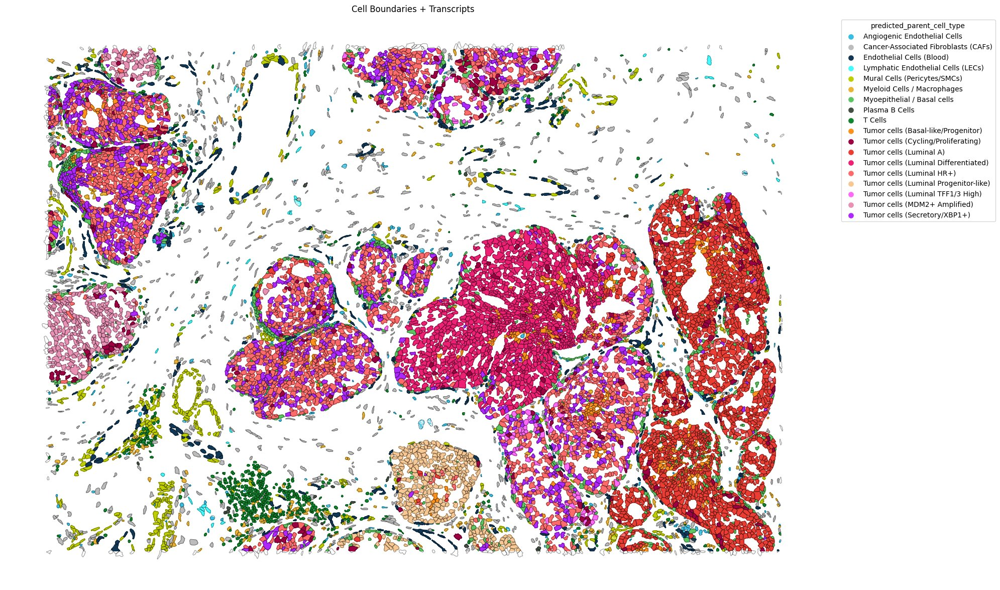

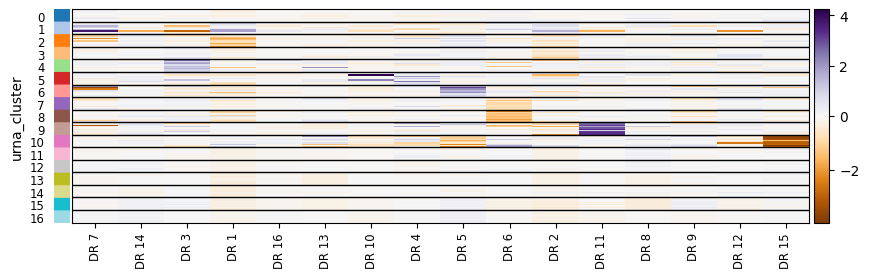

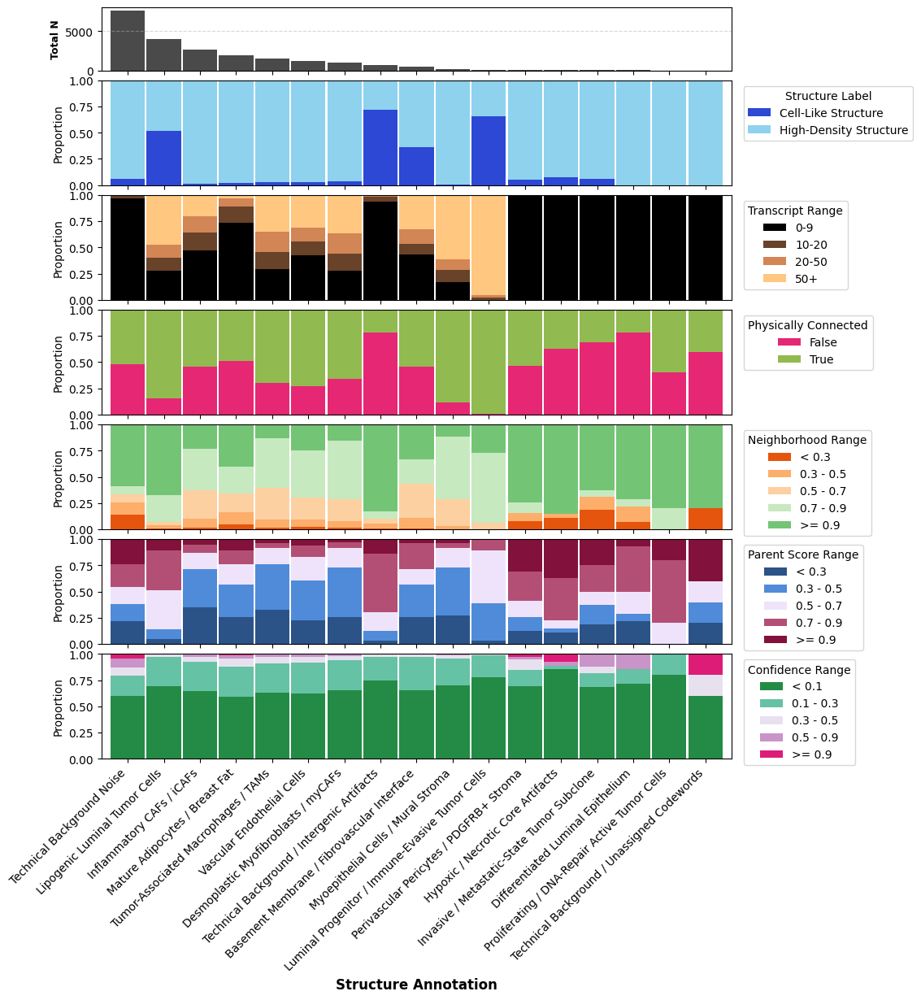

In [82]:
import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# --- 1. DATA PROCESSING & VARIABLE CREATION ---

# Clean structure_annotation strings (remove text in parentheses)
short_anno = (
    sdata["structure_table"]
    .obs["structure_annotation"]
    .astype(str)
    .str.replace(r"\s*\(.*?\)", "", regex=True)
)

# Total counts per structural annotation for the top tracking bar
total_counts = short_anno.value_counts()

# Bin n_transcripts into custom categorical ranges
transcript_bins = pd.cut(
    sdata["structure_table"].obs["n_transcripts"],
    bins=[-float("inf"), 9, 20, 50, float("inf")],
    labels=["0-9", "10-20", "20-50", "50+"],
)

# Bin neighborhood scores into custom intervals
score_bins = pd.cut(
    sdata["structure_table"].obs["neighborhood_score"],
    bins=[-float("inf"), 0.3, 0.5, 0.7, 0.9, float("inf")],
    labels=["< 0.3", "0.3 - 0.5", "0.5 - 0.7", "0.7 - 0.9", ">= 0.9"],
)

# Bin parent scores into custom intervals
parent_score_bins = pd.cut(
    sdata["structure_table"].obs["parent_score"],
    bins=[-float("inf"), 0.3, 0.5, 0.7, 0.9, float("inf")],
    labels=["< 0.3", "0.3 - 0.5", "0.5 - 0.7", "0.7 - 0.9", ">= 0.9"],
)

# Bin assignment confidence into custom intervals
conf_bins = pd.cut(
    sdata["structure_table"].obs["assignment_confidence"],
    bins=[-float("inf"), 0.1, 0.3, 0.5, 0.9, float("inf")],
    labels=["< 0.1", "0.1 - 0.3", "0.3 - 0.5", "0.5 - 0.9", ">= 0.9"],
)

# --- 2. GENERATE AND NORMALIZE ALL CROSS-TABULATIONS ---

# Ensure consistent index order across all structures based on total counts
structure_order = total_counts.index

def get_normalized_crosstab(v2):
    ct = pd.crosstab(short_anno, v2)
    ct = ct.reindex(structure_order)
    return ct.div(ct.sum(axis=1), axis=0)

df_label = get_normalized_crosstab(sdata["structure_table"].obs["structure_label"])
df_trans = get_normalized_crosstab(transcript_bins)
df_conn  = get_normalized_crosstab(sdata["structure_table"].obs["is_physically_connected"])
df_neigh = get_normalized_crosstab(score_bins)
df_paren = get_normalized_crosstab(parent_score_bins)
df_conf  = get_normalized_crosstab(conf_bins)

# --- 3. RENDER COMPACT PLOT (SHARED X-AXIS) ---

# 1 Top metadata bar + 6 relative panels. Height ratios make the top bar much thinner.
fig, axes = plt.subplots(
    7, 1, figsize=(10, 12), sharex=True, 
    gridspec_kw={'height_ratios': [0.6, 1, 1, 1, 1, 1, 1]}
)
width_val = 0.95

# Panel 0: Top Total Counts indicator bar (Raw values plotted, but kept small)
total_counts.reindex(structure_order).plot(kind="bar", color="#4a4a4a", width=width_val, ax=axes[0])
axes[0].set_ylabel("Total N", fontsize=9, weight="bold")
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Panel 1: Structure Label
df_label.plot(kind="bar", stacked=True, width=width_val, ax=axes[1], color=["#2c48d4", "#8ed2ed"])
axes[1].legend(title="Structure Label", bbox_to_anchor=(1.01, 1), loc="upper left")

# Panel 2: Transcript Ranges
df_trans.plot(kind="bar", stacked=True, width=width_val, ax=axes[2], cmap="copper")
axes[2].legend(title="Transcript Range", bbox_to_anchor=(1.01, 1), loc="upper left")

# Panel 3: Physical Connection
df_conn.plot(kind="bar", stacked=True, width=width_val, ax=axes[3], color=["#e62773", "#91ba50"])
axes[3].legend(title="Physically Connected", bbox_to_anchor=(1.01, 1), loc="upper left")

# Panel 4: Neighborhood Score
custom_colors_neighborhood = ["#e6550d", "#fdae6b", "#fdd0a2", "#c7e9c0", "#74c476"]
df_neigh.plot(kind="bar", stacked=True, width=width_val, ax=axes[4], color=custom_colors_neighborhood)
axes[4].legend(title="Neighborhood Range", bbox_to_anchor=(1.01, 1), loc="upper left")

# Panel 5: Parent Score
custom_colors_parent = ["#2b5387", "#508bd9", "#efe3fc", "#b34f75", "#82113c"]
df_paren.plot(kind="bar", stacked=True, width=width_val, ax=axes[5], color=custom_colors_parent)
axes[5].legend(title="Parent Score Range", bbox_to_anchor=(1.01, 1), loc="upper left")

# Panel 6: Assignment Confidence (Cool-to-warm teal-to-plum variant palette)
custom_colors_conf = ["#238b45", "#66c2a4", "#e7e1ef", "#c994c7", "#dd1c77"]
df_conf.plot(kind="bar", stacked=True, width=width_val, ax=axes[6], color=custom_colors_conf)
axes[6].legend(title="Confidence Range", bbox_to_anchor=(1.01, 1), loc="upper left")

# Standardize y-labels for all relative distribution plots
for ax in axes[1:]:
    ax.set_ylabel("Proportion", fontsize=10)
    ax.set_ylim(0, 1)

# Format bottom shared layout plane
axes[-1].set_xlabel("Structure Annotation", fontsize=12, weight="bold")
plt.xticks(rotation=45, ha="right")

# Adjust spaces tightly since titles are eliminated
plt.subplots_adjust(hspace=0.10)

# --- 4. EXPORT ---
output_filename = "compact_relative_structure_metrics_dashboard.pdf"
plt.savefig(
    os.path.join(saving_path, output_filename),
    bbox_inches="tight",
    format="pdf",
    dpi=300,
)
plt.show()

# Morphology plots

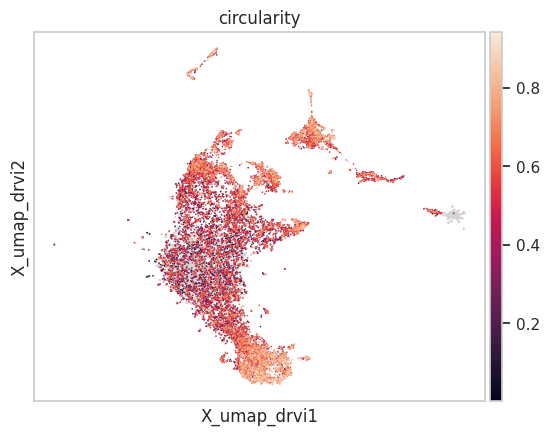

In [42]:
sc.pl.embedding(sdata['structure_table'],basis='X_umap_drvi',color='circularity')

In [43]:
plot_config = {"points_key": "transcripts","x_col": "cosine_similarity", 
"y_col": "cosine_sim_stainings", "hue_col": "enrichment_class",  
# "gene_list": ["Camk2a"],  # Even if this is commented out or missing, it won't crash!
"s": 0.02, "alpha": 0.90, "palette_name": "30colors","subsample_fraction": 0.01}

# 3. Execute the optimized comparison function
g = pl.point_metric_comparison(sdata, **plot_config)
genes = plot_config.get('gene_list', [])
gene_suffix = f"_{'_'.join(genes)}" if genes else "_all_genes"
subsample_suffix = f"_subsample{plot_config['subsample_fraction']}" if "subsample_fraction" in plot_config else ""

# Construct the final filename
pdf_filename = f"joint_{plot_config['points_key']}_{plot_config['x_col']}_vs_{plot_config['y_col']}_by_{plot_config['hue_col']}{gene_suffix}{subsample_suffix}.pdf"
g.savefig(saving_path / pdf_filename, bbox_inches="tight", dpi=300)


KeyError: ['cosine_sim_stainings']

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def visualize_composite_staining_intensity_alpha(
    sdata,
    trans_df,  # Base transcripts dataframe for range calculation
    image_key: str = "morphology_focus",
    scale_key: str = "scale0",
    roi: tuple[float, float, float, float] | None = None,
    figsize: tuple[float, float] = (10, 10),
    include_channels: list[int] | None = None,  # NEW: Explicit list of channel indices to plot
    cmaps: list[str] | None = None,            # List of continuous colormaps matching selected channels
    title: str = "Composite Staining (Intensity-Based Alpha)",
    saving_path: Path | str | None = None,
    max_pct:float=98
):
    """
    Creates an aligned composite visualization of chosen staining channels.
    Pixels map their signal intensity directly to their transparency channel.
    Automatically excludes the final dummy channel.
    """
    print("\n=== [1/5] Transcript Global Ranges (Baseline calculation) ===")
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    t_dx, t_dy = t_xmax - t_xmin, t_ymax - t_ymin

    print("\n=== [2/5] Raw Image Metadata (Scale0) ===")
    node = sdata.images[image_key][scale_key]
    img_dask_array = node.image.data if hasattr(node, "image") else node.data
    img_shape = img_dask_array.shape  # (c, y, x)
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]

    print("\n=== [3/5] Scaling Factor Derivation ===")
    scale_x, scale_y = img_w / t_dx, img_h / t_dy
    scale_factor = (scale_x + scale_y) / 2

    if roi is not None:
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = roi
        shifted_xmin, shifted_xmax = roi_xmin - t_xmin, roi_xmax - t_xmin
        shifted_ymin, shifted_ymax = roi_ymin - t_ymin, roi_ymax - t_ymin
        
        pixel_xmin = max(0, int(np.floor(shifted_xmin * scale_factor)))
        pixel_xmax = min(img_w, int(np.ceil(shifted_xmax * scale_factor)))
        pixel_ymin = max(0, int(np.floor(shifted_ymin * scale_factor)))
        pixel_ymax = min(img_h, int(np.ceil(shifted_ymax * scale_factor)))
        
        cropped_img_dask = img_dask_array[:, pixel_ymin:pixel_ymax, pixel_xmin:pixel_xmax]
    else:
        cropped_img_dask = img_dask_array
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = t_xmin, t_xmax, t_ymin, t_ymax

    print("\n=== [4/5] Composite Processing (Filtering Selected Indices) ===")
    if "c" in node.coords:
        full_channel_names = [str(ch) for ch in node.coords["c"].values]
    else:
        full_channel_names = [f"Channel_{i}" for i in range(img_c)]
    
    # Baseline non-dummy channels list
    valid_channel_names = full_channel_names[:-1]
    
    # Compute the cropped pixel subset into RAM safely
    cropped_pixel_matrix = cropped_img_dask.compute()
    valid_pixel_data = cropped_pixel_matrix[:-1, :, :]
    
    # If no target subset is passed, default to all non-dummy indices
    if include_channels is None:
        include_channels = list(range(len(valid_channel_names)))
        
    final_channels_to_plot = []
    final_pixel_data_list = []
    
    for idx in include_channels:
        if idx >= len(valid_channel_names) or idx < 0:
            print(f"-> [WARNING] Requested index {idx} out of range or maps to dummy channel. Skipping.")
            continue
        final_channels_to_plot.append(valid_channel_names[idx])
        final_pixel_data_list.append(valid_pixel_data[idx, :, :])
        
    print(f"-> Actively plotting selected channels: {final_channels_to_plot} (Indices: {include_channels})")
    
    # Ensure fallback colormaps list aligns with the length of chosen channels
    if cmaps is None:
        standard_palette = ['Blues', 'Greens', 'Oranges', 'Reds', 'Purples', 'YlOrBr']
        cmaps = standard_palette[:len(final_channels_to_plot)]
        if len(cmaps) < len(final_channels_to_plot):
            cmaps += ['viridis'] * (len(final_channels_to_plot) - len(cmaps))

    if len(cmaps) < len(final_channels_to_plot):
        raise ValueError(f"Length of provided colormaps list ({len(cmaps)}) does not match selected channels ({len(final_channels_to_plot)})")

    # 5. Render and Export Figure using structural RGBA blending
    print("\n=== [5/5] Plotting Intensity-Alpha Blended Figure ===")
    fig, ax = plt.subplots(figsize=figsize)
    extent = [roi_xmin, roi_xmax, roi_ymin, roi_ymax]
    handles = [] 
    
    for idx, ch_name in enumerate(final_channels_to_plot):
        single_channel_data = final_pixel_data_list[idx]
        
        # Normalize intensities using robust percentiles to clean background noise
        v_min, v_max = np.percentile(single_channel_data, (1, max_pct))
        if v_max == v_min: v_max += 1e-5
        normalized_data = (single_channel_data - v_min) / (v_max - v_min)
        normalized_data = np.clip(normalized_data, 0, 1)
        
        # Convert the 2D intensity profile into a mapped 3D RGB grid based on colormap
        cmap_lookup = plt.get_cmap(cmaps[idx])
        rgba_image = cmap_lookup(normalized_data)  # (Y, X, 4)
        
        # Overwrite alpha layer directly with the normalized signal intensity
        rgba_image[..., 3] = normalized_data 
        
        # Render the pre-compiled RGBA layer
        ax.imshow(
            rgba_image, 
            origin="lower", 
            extent=extent
        )
        
        # Setup legend tags using the color high-point
        marker_color = cmap_lookup(0.8)
        handles.append(plt.Line2D([0], [0], color=marker_color, lw=4, label=ch_name))

    ax.set_title(title, fontweight='bold', fontsize=12)
    ax.axis("off")
    ax.legend(handles=handles, title="Stainings", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    plt.tight_layout()
    
    if saving_path is not None:
        save_dir = Path(saving_path)
        save_dir.mkdir(parents=True, exist_ok=True)
        roi_suffix = f"_roi_{int(roi_xmin)}_{int(roi_xmax)}" if roi is not None else ""
        ch_suffix = f"_channels_" + "_".join(map(str, include_channels))
        pdf_filename = f"staining_composite{ch_suffix}_intensity_alpha{roi_suffix}.pdf"
        
        fig.savefig(save_dir / pdf_filename, bbox_inches="tight", dpi=300)
        print(f"-> Intensity-alpha composite PDF saved: {pdf_filename}")
        
    plt.show()
    plt.close(fig)

In [48]:
# Pull the base transcript array out of the Dask environment to acquire baseline ranges
transcripts_base_df = sdata["transcripts"][['x', 'y', 'z', 'gene', 'cell_id']].compute()

visualize_composite_staining_intensity_alpha(
    sdata=sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=(4900, 5100, 2100, 2400),
    figsize=(10, 10),
    include_channels=[0, 2, 3],               # Target array selection
    cmaps=['YlGnBu', 'YlGn', 'YlOrRd'],        # 3 colormaps matching your 3 indices
    saving_path=saving_path,max_pct=99.5
)


=== [1/5] Transcript Global Ranges (Baseline calculation) ===

=== [2/5] Raw Image Metadata (Scale0) ===


KeyError: 'morphology_focus'

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/atera_hsbreast/data_with_source_score_optimized_params_annotated_real.zarr
├── Labels
│     ├── 'cell_labels': DataTree[yx] (6900, 10049), (3450, 5024), (1725, 2512), (862, 1256), (432, 628)
│     └── 'nucleus_labels': DataTree[yx] (6900, 10049), (3450, 5024), (1725, 2512), (862, 1256), (432, 628)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 23) (3D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 25) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (11783, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (11645, 2) (2D shapes)
│     ├── 'grid_squares': GeoDataFrame shape: (31458, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (11608, 1) (2D shapes)
└── Tables
      ├── 'segmentation_free_table': AnnData (14652, 24501)
      ├── 'source_score': AnnData (100779

In [47]:
sdata["transcripts"].columns

Index(['x', 'y', 'z', 'gene', 'cell_id', 'nucleus_distance',
       'overlaps_nucleus', 'codeword_index', 'qv', 'codeword_category',
       'fov_name', 'is_gene', 'transcript_id', 'control_probe',
       'overlaps_cell', 'enrichment_class', 'density_similarity_score',
       'enrichment_over_random', 'local_count_in_radius', 'closest_cell_type',
       'cosine_similarity', 'prob_is_urna', 'extracellular', 'point_source',
       'structure_id'],
      dtype='object')

# We define for each DR their scoring at each uRNA cluster

In [80]:
drvi.utils.pl.plot_latent_dims_in_heatmap(embed, "urna_cluster", title_col="title",cmap='PuOr', sort_by_categorical=True,show=False)
plt.savefig(os.path.join(saving_path,'drvi_on_urna_clusters.pdf'))

In [ ]:
traverse_adata = drvi.utils.tl.traverse_latent(model, embed, n_samples=20, max_noise_std=0.0)
drvi.utils.tl.calculate_differential_vars(traverse_adata)

In [ ]:
embed.write("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/atera_hsbreast/drvi_hbreast_embed_adata.h5ad")
traverse_adata.write("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/atera_hsbreast/drvi_hbreast_traverse_adata.h5ad")

# We read again the embedding object and the gene contribution to the DRs object

In [ ]:
traverse_adata = sc.read("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/atera_hsbreast/drvi_hbreast_traverse_adata.h5ad")
embed= sc.read("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/atera_hsbreast/drvi_hbreast_embed_adata.h5ad")

In [ ]:
drvi.utils.pl.show_top_differential_vars(traverse_adata, key="combined_score", score_threshold=0.0,show=False)
plt.savefig(os.path.join(saving_path,'drvi_deg_by_dr_barplot.pdf'))
drvi.utils.pl.plot_latent_dims_in_umap(embed)

We create embed_filt, which contains only non-vanished dimensions

In [ ]:
embed_filt=embed[:,embed.var['vanished']==False]
embed_filt=embed_filt[:,embed_filt.var.sort_values(by='order').index]

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import os

def plot_gene_set(genes, filename, ncols=5, figsize_base=4):
    n_genes = len(genes)
    nrows = int(np.ceil(n_genes / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_base*ncols, figsize_base*nrows))

    axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]

    for ax, g in zip(axes, genes):
        embed_filt.obsm["spatial"] = spatial_swapped
        sc.pl.spatial(
            embed_filt,
            color=g,  # gene ID
            title=embed_filt.var.loc[g, 'title'],  # show title instead of ID
            spot_size=15,
            cmap="PuOr",
            vcenter=0,
            ax=ax,
            show=False,
            legend_fontsize=10,
        )
        ax.invert_yaxis()
        ax.invert_xaxis()

    # Remove unused subplots
    for ax in axes[n_genes:]:
        ax.remove()

    #plt.tight_layout()
    plt.savefig(os.path.join(saving_path, filename))
    plt.show()

# Restore coords

# Plot both sets
#plot_gene_set(ordered_list, "spatial_map_dr_set1.png")
#plot_gene_set(genes_set2, "spatial_map_dr_set2.png")

#embed_filt.obsm["spatial"] = spatial_swapped[:, [1, 0]]

#plot_gene_set(embed_filt.var.index, "spatial_map_dr_all.png")

In [ ]:
plot_gene_set(embed_filt.var.index, "spatial_map_dr_all.png",ncols=2,figsize_base=7)

# Apply DRs to cells

In [133]:
import scipy.sparse as sp
import scanpy as sc
import pandas as pd

# 1. Access the cell table from SpatialData
new_adata = sdata['table'].copy()

# ── Get the genes the model was trained on ────────────────────────────────────
training_genes = model.adata.var_names

missing_genes  = training_genes.difference(new_adata.var_names)
present_genes  = training_genes.intersection(new_adata.var_names)

print(f"Training genes : {len(training_genes)}")
print(f"Present in new : {len(present_genes)}")
print(f"Missing        : {len(missing_genes)}")

# ── Align to training genes ───────────────────────────────────────────────────
if len(missing_genes) > 0:
    zero_block = sp.csr_matrix((new_adata.n_obs, len(missing_genes)))
    missing_adata = sc.AnnData(
        X   = zero_block,
        obs = new_adata.obs,
        var = pd.DataFrame(index=missing_genes)
    )
    new_adata_aligned = sc.concat([new_adata[:, present_genes], missing_adata], axis=1)
else:
    new_adata_aligned = new_adata[:, present_genes].copy()

# Reorder to exactly match training gene order
new_adata_aligned = new_adata_aligned[:, training_genes].copy()

# ── Add counts layer — model expects adata.layers['counts'] ──────────────────
if 'counts' in new_adata.layers:
    source_layer = new_adata[:, present_genes].layers['counts']
elif 'raw_counts' in new_adata.layers:
    source_layer = new_adata[:, present_genes].layers['raw_counts']
else:
    source_layer = new_adata[:, present_genes].X

if len(missing_genes) > 0:
    zero_counts = sp.csr_matrix((new_adata.n_obs, len(missing_genes)))
    new_adata_aligned.layers['counts'] = sp.hstack([source_layer, zero_counts])
else:
    new_adata_aligned.layers['counts'] = source_layer.copy()

# Ensure correct gene order post-layer attachment
new_adata_aligned = new_adata_aligned[:, training_genes].copy()

# ── Encode Latent Representation ──────────────────────────────────────────────
latent = model.get_latent_representation(new_adata_aligned, give_mean=True)
new_adata_aligned.obsm['X_drvi'] = latent
print(f"Latent shape: {latent.shape}")

# ── Optional: Compute UMAP & Clustering on Aligned Data ──────────────────────
# (Ensuring keys exist to match your structure example structure exactly)
if 'X_umap' not in new_adata_aligned.obsm:
    sc.pp.neighbors(new_adata_aligned, use_rep="X_drvi")
    sc.tl.umap(new_adata_aligned)

if 'urna_cluster' not in new_adata_aligned.obs:
    sc.tl.leiden(new_adata_aligned, key_added='urna_cluster')


# ==============================================================================
# ── SAVE TO SpatialData['table'] (Structure-identical format) ──────────────────
# ==============================================================================

# 1. Store the raw latent embedding matrix (X_drvi)
sdata["table"].obsm["X_drvi"] = new_adata_aligned.obsm["X_drvi"]

# 2. Store the coordinate embedding for visualization spaces
sdata["table"].obsm["X_umap_drvi"] = new_adata_aligned.obsm["X_umap"]

# 3. Store categorical metadata classifications
sdata["table"].obs["urna_cluster"] = new_adata_aligned.obs["urna_cluster"]

# 4. Store dimensionality factor information (features/variance metadata statistics)
sdata['table'].uns['drvi_dr_stats'] = new_adata_aligned.var.copy()

print("Successfully written DR representation arrays into sdata['table'].")

Training genes : 24501
Present in new : 17992
Missing        : 6509
INFO     Input AnnData not setup with scvi-tools. attempting to transfer AnnData setup                             
Latent shape: (11640, 128)
Successfully written DR representation arrays into sdata['table'].


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

cell_type_key = 'leiden'

# ── Filter to non-vanished DRs using embed.var ────────────────────────────────
non_vanished = embed.var[~embed.var['vanished']].sort_values('order')
active_dims  = non_vanished['original_dim_id'].tolist()   # column indices in X_drvi
active_titles = non_vanished['title'].tolist()             # e.g. "DR 1", "DR 2" ...

print(f"Active (non-vanished) DRs: {len(active_dims)}")

# ── Build DR score dataframe from latent representation ───────────────────────
df = pd.DataFrame(
    new_adata.obsm['X_drvi'][:, active_dims],
    index=new_adata.obs_names,
    columns=active_titles
)
df[cell_type_key] = new_adata.obs[cell_type_key].values
cell_type_order   = sorted(df[cell_type_key].unique())

# ── 1. Heatmap ────────────────────────────────────────────────────────────────
mean_scores = df.groupby(cell_type_key)[active_titles].mean().loc[cell_type_order]

fig, ax = plt.subplots(figsize=(len(active_titles) * 0.7, len(cell_type_order) * 0.5 + 2))
sns.heatmap(
    mean_scores,
    cmap='PuOr', center=0,
    linewidths=0.3, linecolor='white',
    xticklabels=True, yticklabels=True,
    ax=ax
)
ax.set_title('Mean DR score by cell type (non-vanished DRs)',
             fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('DR dimension')
ax.set_ylabel('Cell type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(saving_path, 'dr_scores_celltype_heatmap.pdf'),
            bbox_inches='tight')
plt.show()

# ── 2. Violin ─────────────────────────────────────────────────────────────────
df_long = df.melt(id_vars=cell_type_key, var_name='DR', value_name='score')

n_drs = len(active_titles)
ncols = 4
nrows = int(np.ceil(n_drs / ncols))

fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 5, nrows * 3.5),
                         sharey=False)
axes = np.array(axes).flatten()

for ax, dr in zip(axes, active_titles):
    sns.violinplot(
        data=df_long[df_long['DR'] == dr],
        x=cell_type_key,
        y='score',
        order=cell_type_order,
        ax=ax,
        inner='box',
        linewidth=0.7,
        color='steelblue',
        scale='width',
    )
    ax.axhline(0, color='grey', linewidth=0.7, linestyle='--')
    ax.set_title(dr, fontsize=10, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('score', fontsize=8)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=7)
    ax.yaxis.grid(True, linewidth=0.5, color='#E2E4E7')
    ax.set_axisbelow(True)

for ax in axes[n_drs:]:
    ax.set_visible(False)

fig.suptitle('DR scores by cell type (non-vanished)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(saving_path, 'dr_scores_celltype_violin.pdf'),
            bbox_inches='tight')
plt.show()

In [ ]:
# ── Plot non-vanished DR scores on UMAP ───────────────────────────────────────
# assumes new_adata has .obsm['X_umap'] already computed
# if not: sc.pp.neighbors(new_adata, use_rep='X_drvi'); sc.tl.umap(new_adata)

# store DR scores in obs so sc.pl.umap can access them
for dim, title in zip(active_dims, active_titles):
    new_adata.obs[title] = new_adata.obsm['X_drvi'][:, dim]

n_drs  = len(active_titles)
ncols  = 4
nrows  = int(np.ceil(n_drs / ncols))

fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 4, nrows * 3.5))
axes = np.array(axes).flatten()

for ax, title in zip(axes, active_titles):
    sc.pl.umap(
        new_adata,
        color=title,
        cmap='PuOr',
        vcenter=0,
        ax=ax,
        show=False,
        frameon=False,
        colorbar_loc='right',
        title=title,
        s=10,
    )

for ax in axes[n_drs:]:
    ax.set_visible(False)

fig.suptitle('DR scores on UMAP (non-vanished)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(saving_path, 'dr_scores_umap.pdf'), bbox_inches='tight')
plt.show()

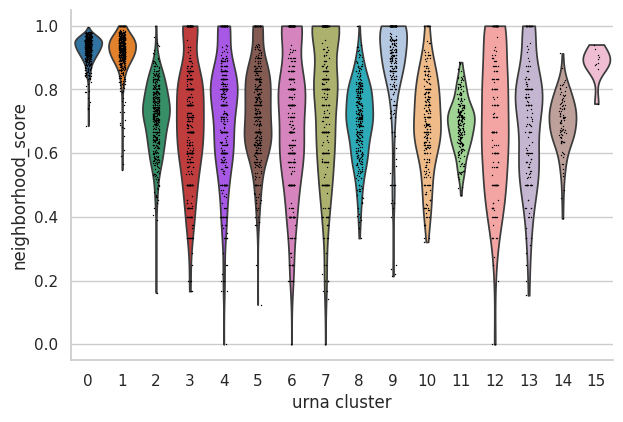

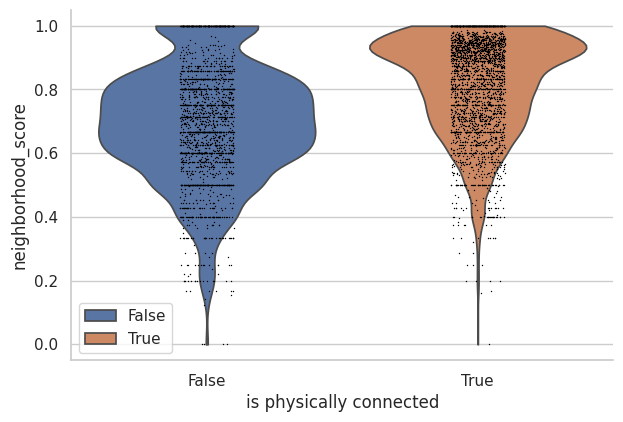

(0.0, 500.0)

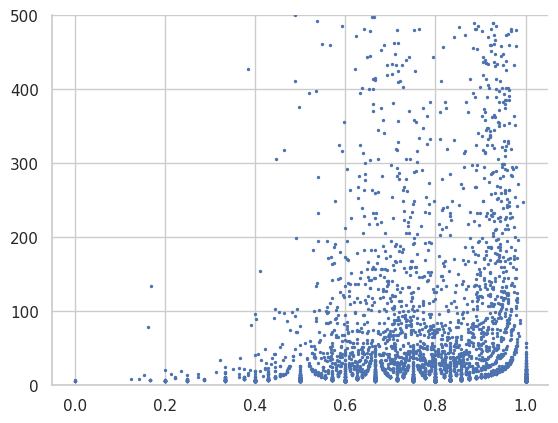

In [174]:
sdata['structure_table'].obs['is_physically_connected']=sdata['structure_table'].obs['is_physically_connected'].astype('category')
sc.pl.violin(sdata['structure_table'],['neighborhood_score'],groupby='urna_cluster')
sc.pl.violin(sdata['structure_table'],['neighborhood_score'],groupby='is_physically_connected')
plt.scatter(sdata['structure_table'].obs['neighborhood_score'],sdata['structure_table'].obs['n_transcripts'],s=2)
plt.ylim([0,500])
#plt.yscale('log')

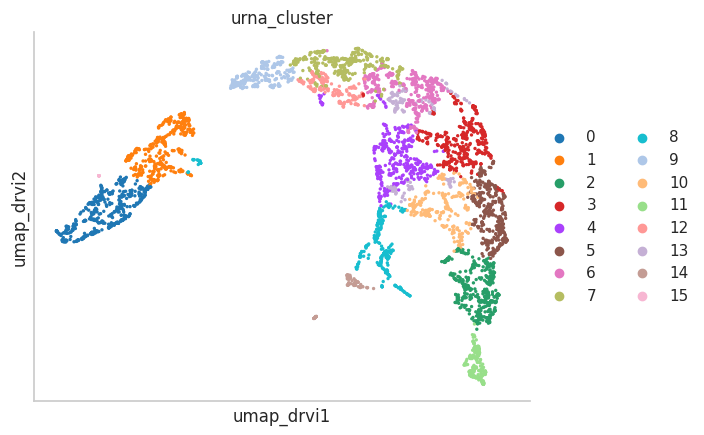

In [162]:
sc.pl.embedding(sdata['structure_table'], color='urna_cluster', basis='umap_drvi')

# Check structure's uRNA clusters vs image-intensities 

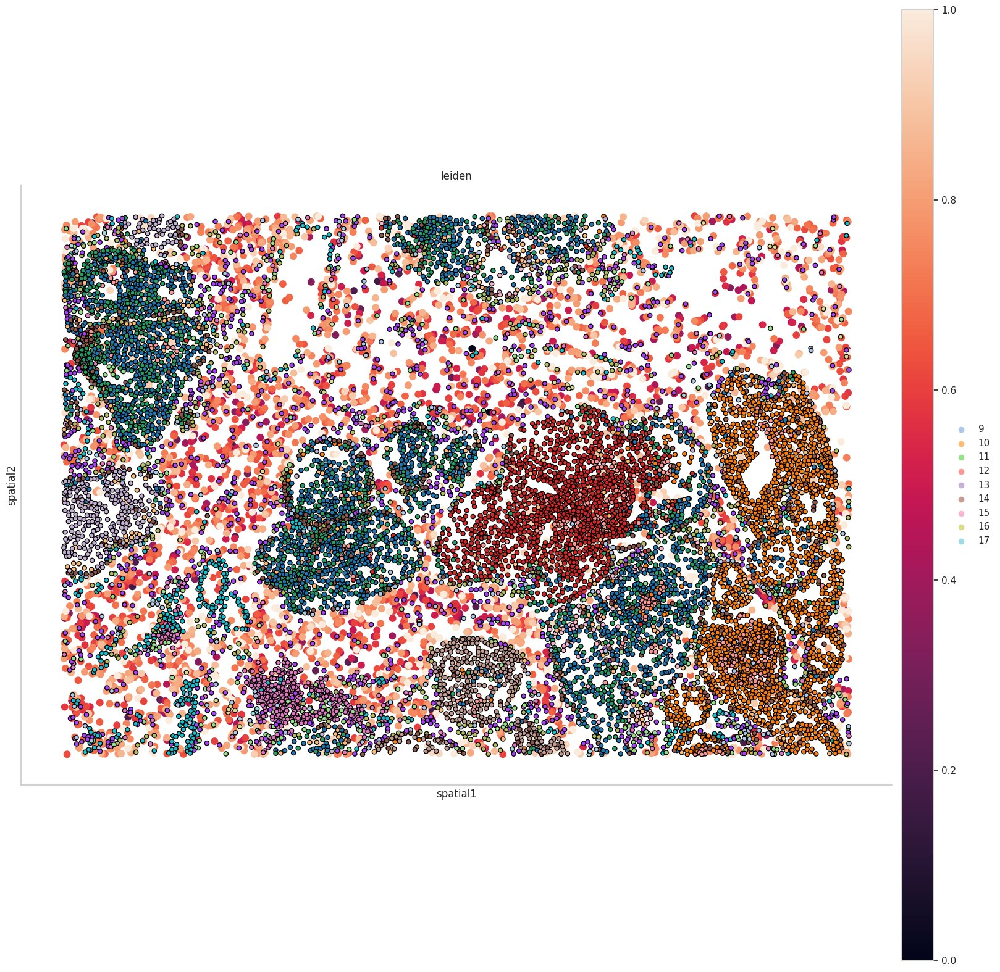

In [169]:
import matplotlib.pyplot as plt
import scanpy as sc

# 1. Create a larger figure and axis
fig, ax = plt.subplots(figsize=(20, 20))

# 2. Plot the first layer
sc.pl.spatial(
    sdata['structure_table'],
    color='neighborhood_score',
    spot_size=20,
    ax=ax,
    show=False
)

# 3. Plot the second layer with cell outlines
sc.pl.spatial( 
    sdata['table'],
    color='leiden',
    spot_size=12, 
    ax=ax,
    show=False,
    edgecolor='black',  # Sets the outline color (e.g., 'white', 'black', or 'none')
    linewidth=1.0       # Sets the thickness of the outline
)

# 4. Display the combined plot
plt.show()

Successfully saved editable vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/atera_hsbreast/structure_circularity_comparison.pdf


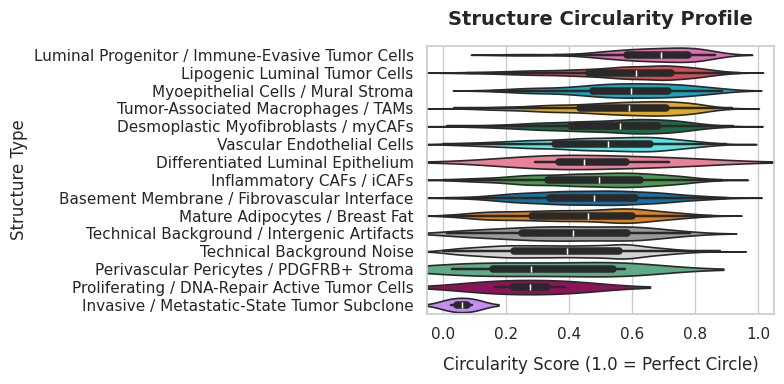

In [62]:
# Call the visualizer with your specific configurations
plot_structure_circularity(
    sdata=sdata,
    table_key="structure_table",
    group_key="structure_annotation",  # Adjust this if your metadata column name varies
    saving_path=os.path.join(saving_path,"structure_circularity_comparison.pdf"),figsize=(8,4))

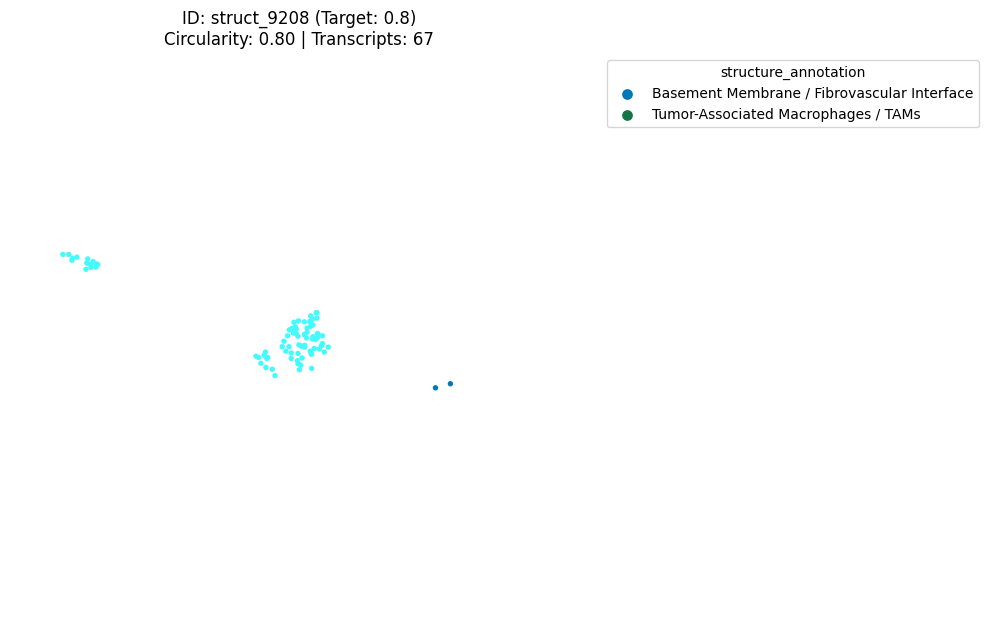


--- Processing Target Circularity: 0.9 ---
  [1/3] Struct: struct_11863 | Circ: 0.901 | N: 294


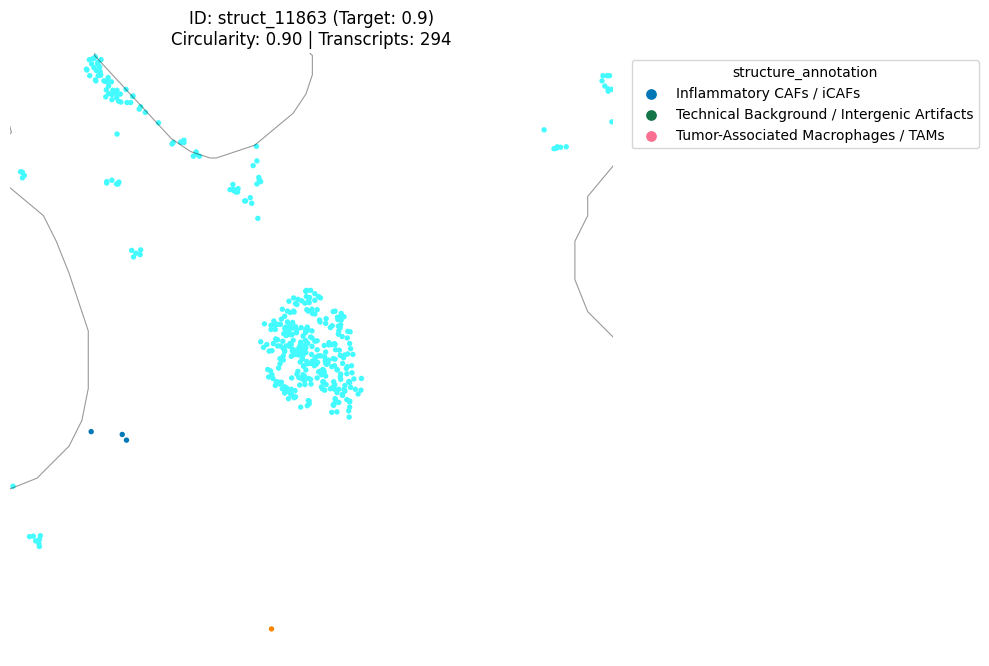

  [2/3] Struct: struct_3659 | Circ: 0.902 | N: 1954


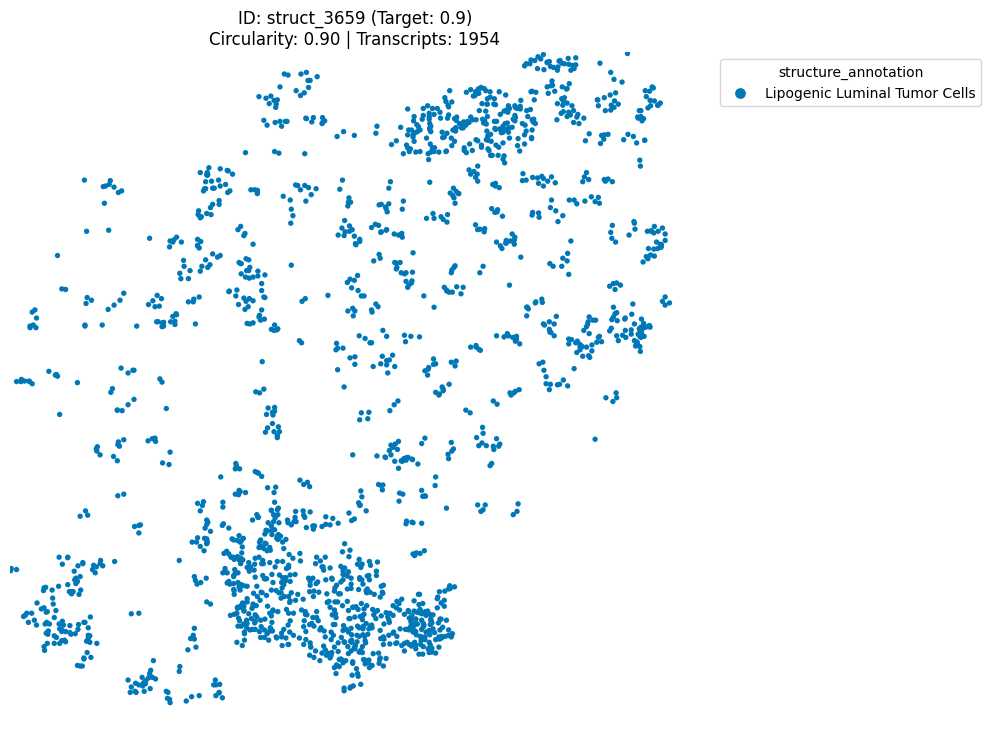

  [3/3] Struct: struct_17535 | Circ: 0.898 | N: 20


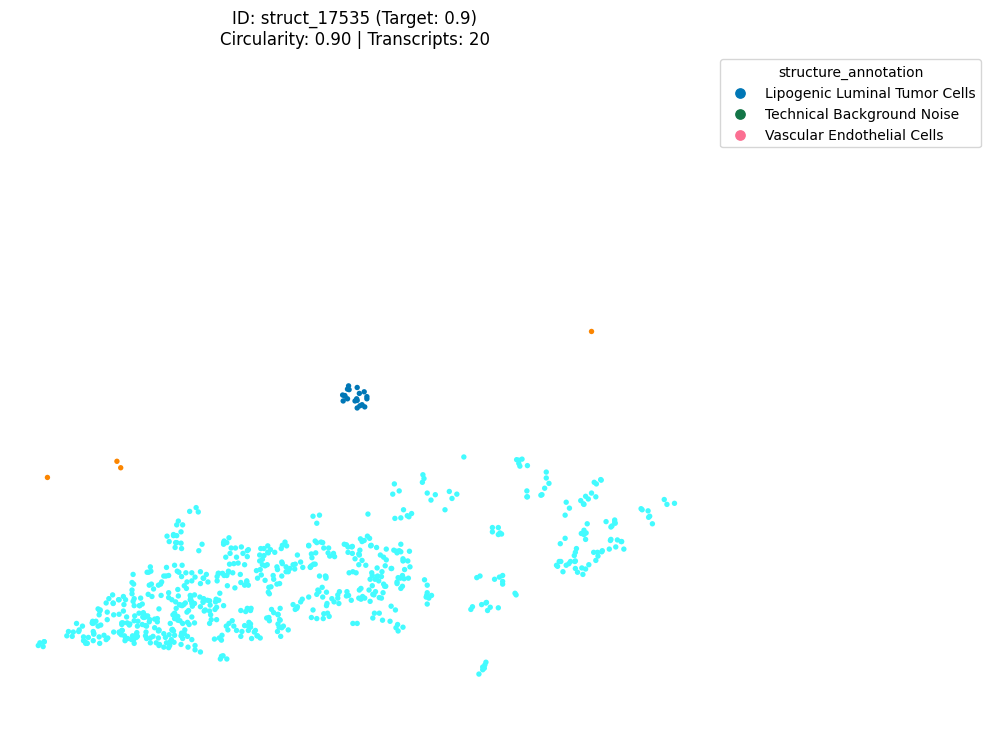


--- Processing Target Circularity: 1.0 ---
  [1/3] Struct: struct_1769 | Circ: 0.916 | N: 58


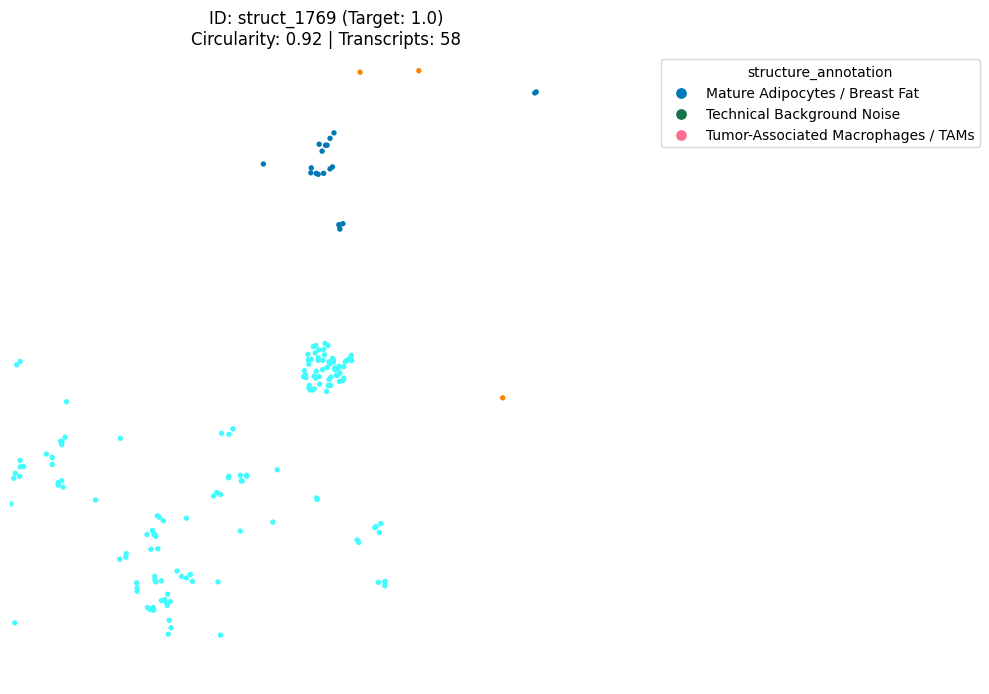

  [2/3] Struct: struct_10882 | Circ: 0.903 | N: 33


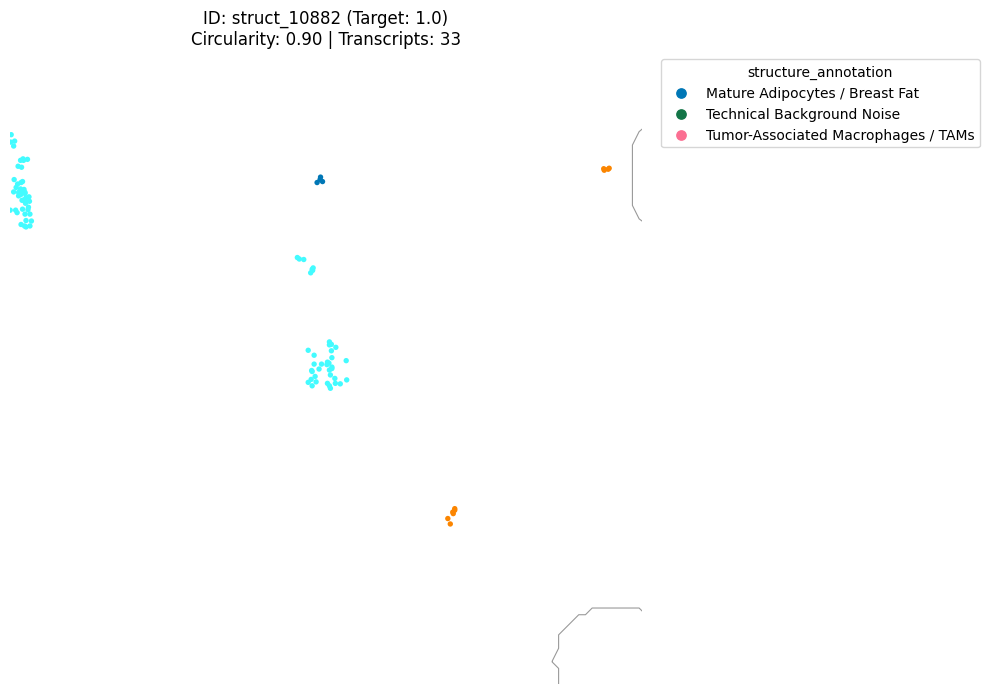

  [3/3] Struct: struct_3659 | Circ: 0.902 | N: 1954


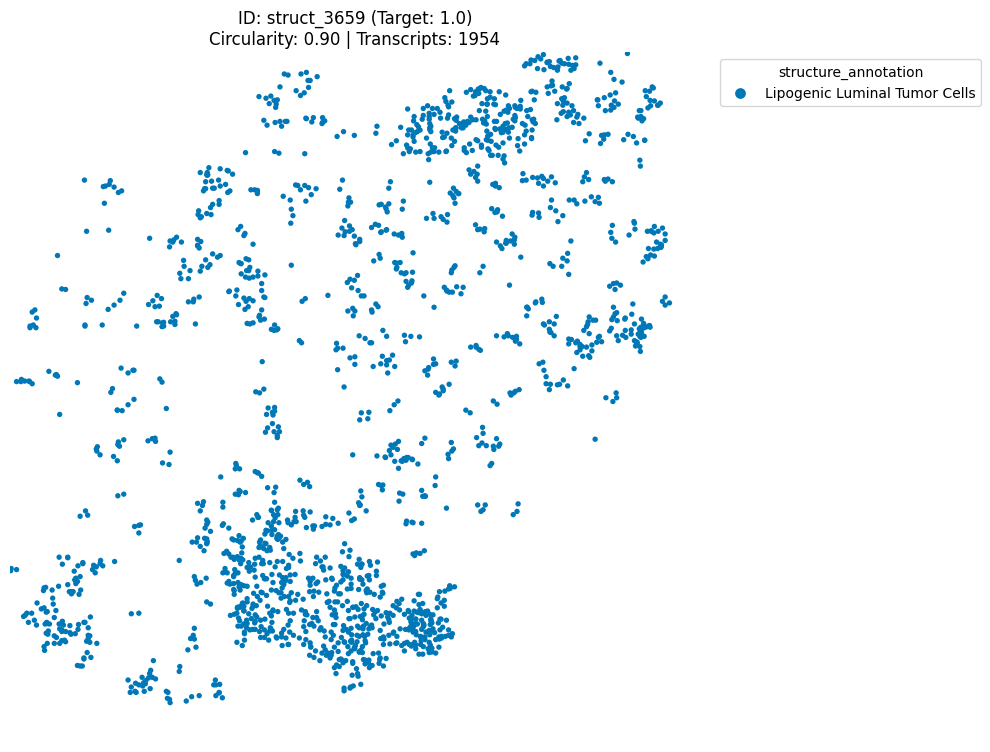


🎉 Batch export successfully completed!


In [11]:
import os
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. SETUP COLORMAP AND PATH ENGINE
# ==============================================================================
scanpy_colors = sdata["structure_table"].uns["structure_annotation_colors"]
sdata["structure_table"].obs["structure_annotation"] = (
    sdata["structure_table"].obs["structure_annotation"].astype(str)
)
scanpy_cmap = mcolors.ListedColormap(scanpy_colors)

obs_df = sdata["structure_table"].obs
min_transcripts_threshold = 20
padding = 10.0

# Pre-filter for structures that satisfy the transcript minimum limit 
# AND are NOT physically connected to a segmented cell boundary
valid_structures = obs_df[
    (obs_df["n_transcripts"] >= min_transcripts_threshold) & 
    (obs_df["is_physically_connected"] == False)
]

if len(valid_structures) < 3:
    raise ValueError(
        f"Not enough disconnected structures contain >= {min_transcripts_threshold} transcripts. "
        f"Found only {len(valid_structures)} matching candidate structures."
    )

# Define target milestones from 0.1 to 1.0
target_ranges = np.linspace(0.1, 1.0, 10)

print(f"Starting automated batch ROI export engine (Disconnected Structures Only)...")

# ==============================================================================
# 2. BATCH ITERATION SPECTRUM LOOP
# ==============================================================================
for target in target_ranges:
    print(f"\n--- Processing Target Circularity: {target:.1f} ---")
    
    # Calculate absolute delta difference to target milestone
    absolute_diff = (valid_structures["circularity"] - target).abs()
    
    # Extract the top 3 distinct closest matching structures
    closest_indices = absolute_diff.nsmallest(3).index
    
    for rank, idx in enumerate(closest_indices, start=1):
        target_structure = valid_structures.loc[idx]
        
        struct_x = target_structure["x"]
        struct_y = target_structure["y"]
        actual_circularity = target_structure["circularity"]
        num_transcripts = target_structure["n_transcripts"]
        
        print(f"  [{rank}/3] Struct: {idx} | Circ: {actual_circularity:.3f} | N: {num_transcripts}")
        
        # Calculate localized 20-pixel padding boundary window
        computed_roi = (
            struct_x - padding,
            struct_x + padding,
            struct_y - padding,
            struct_y + padding,
        )
        
        # Turn off interactive plotting popups during a large batch process
        plt.ioff()
        
        # Render the custom ROI panel
        fig, ax = pl.spatial_transcripts(
            sdata,
            color_key="structure_annotation",
            colormap=scanpy_cmap,
            scatter_size=10,
            use_roi=True,              
            roi=computed_roi,          
            figsize=(10, 10),          
            boundary_linewidth=0.8,
            alpha=1,
            rasterize=True,
            missing_val_sentinel=-1,
            title=f"ID: {idx} (Target: {target:.1f})\nCircularity: {actual_circularity:.2f} | Transcripts: {num_transcripts}"
        )
        
        # Build systematic file token name
        file_name = f"roi_disconnected_target_{target:.1f}_rank{rank}_id{idx}_circ{actual_circularity:.2f}.pdf"
        output_file_path = os.path.join(saving_path, file_name)
        
        # Save structural vector image layout sheet
        fig.savefig(output_file_path, bbox_inches="tight", format="pdf")
        plt.show()
        plt.close(fig)  # Clear graphic baseline buffer memory leaks

# Re-enable interactive layout settings once execution terminates
plt.ion()
print("\n🎉 Batch export successfully completed!")

# Data characteristics

In [12]:
import numpy as np

# 1. Pull the data series for cleaner access
is_connected = sdata['structure_table'].obs['is_physically_connected']
struct_counts = sdata['structure_table'].obs['n_transcripts']
cell_counts = sdata['table'].obs['transcript_counts']

# 2. Compute the values
total_structures = len(is_connected)
pct_connected = np.sum(is_connected) / total_structures
pct_disconnected = 1.0 - pct_connected

median_struct_transcripts = np.median(struct_counts)
median_cell_transcripts = np.median(cell_counts)
transcript_ratio = median_struct_transcripts / median_cell_transcripts

# 3. Print structured diagnostic dashboard
print("=" * 60)
print("🎯 STRUCTURE SEGMENTATION & METRIC SUMMARY")
print("=" * 60)
print(f"Total Candidate Structures Evaluated : {total_structures:,}")
print("-" * 60)
print(f"🟢 Physically Connected to Cells     : {pct_connected:.2%} ({np.sum(is_connected):,})")
print(f"⚪ Free-standing / Disconnected       : {pct_disconnected:.2%} ({total_structures - np.sum(is_connected):,})")
print("-" * 60)
print(f"📊 Median Transcripts per Structure  : {median_struct_transcripts:.1f}")
print(f"🧬 Median Transcripts per Parent Cell : {median_cell_transcripts:.1f}")
print(f"📈 Size Ratio (Structure / Cell)    : {transcript_ratio:.4f} (~{transcript_ratio:.2%})")
print("=" * 60)

🎯 STRUCTURE SEGMENTATION & METRIC SUMMARY
Total Candidate Structures Evaluated : 21,488
------------------------------------------------------------
🟢 Physically Connected to Cells     : 60.60% (13,021)
⚪ Free-standing / Disconnected       : 39.40% (8,467)
------------------------------------------------------------
📊 Median Transcripts per Structure  : 5.0
🧬 Median Transcripts per Parent Cell : 2586.5
📈 Size Ratio (Structure / Cell)    : 0.0019 (~0.19%)


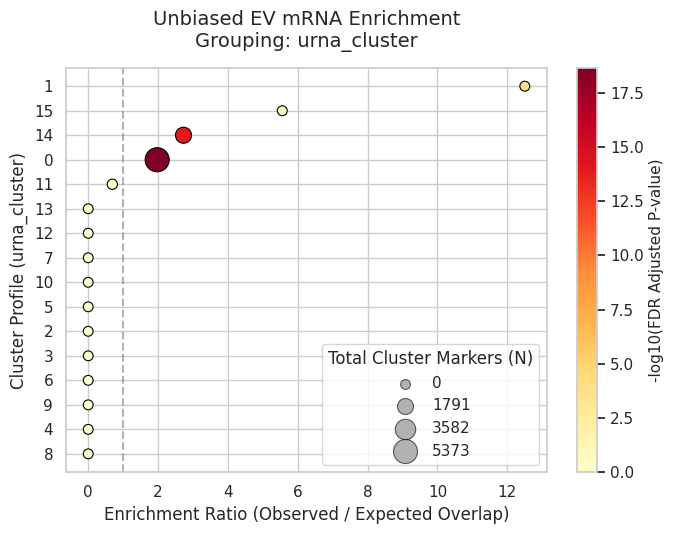

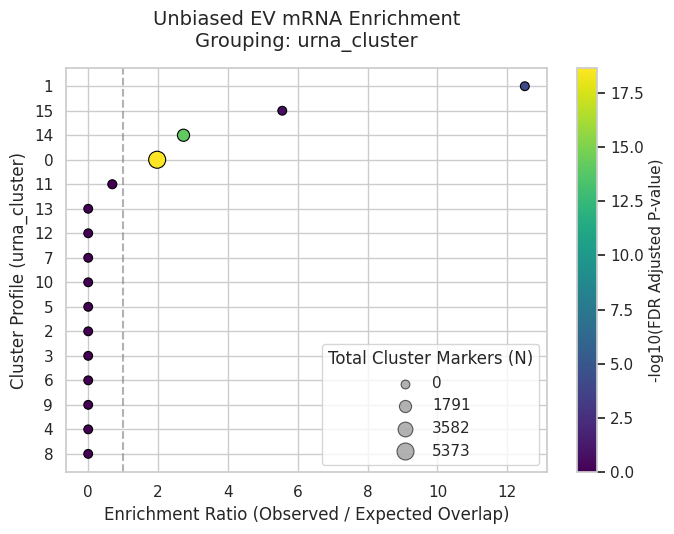

In [ ]:
import os
import numpy as np
import pandas as pd
import gseapy as gp
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt

# ==============================================================================
# --- 1. SET PATHS & LOAD ANNOTATIONS ---
# ==============================================================================
syngo_path = '/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ref_databases/syngo1.3_complete_data'
anno_file = os.path.join(syngo_path, 'annotations.xlsx')

df_anno = pd.read_excel(anno_file)
df_anno = df_anno[df_anno['go_domain'] == 'CC']

# Convert SynGO to dictionary (Uppercase for GSEA, converted to match var_names later)
syngo_gs = df_anno.groupby('go_name')['hgnc_symbol'].apply(
    lambda x: list(set(x.dropna().unique()))
).to_dict()
syngo_gs = {name: [str(g).upper() for g in genes] for name, genes in syngo_gs.items()}

print(f"Loaded {len(syngo_gs)} unique SynGO terms for enrichment.")

# ==============================================================================
# --- 2. EXTRACT STRUCTURE ANNDATA OBJECT ---
# ==============================================================================
# Extract an isolated copy of the structure table to process locally
struct_adata = sdata["structure_table"].copy()

# Automatically discover the case formatting used in your dataset's genes
# (Checks if first gene name is fully uppercase, lowercase, or Title Case)
sample_gene = str(struct_adata.var_names[0])
if sample_gene.isupper():
    gene_formatter = lambda g: str(g).upper()
elif sample_gene.islower():
    gene_formatter = lambda g: str(g).lower()
else:
    gene_formatter = lambda g: str(g).capitalize()


## SynGO ORA analysis

In [139]:
sc.pp.normalize_total(struct_adata)
sc.pp.log1p(struct_adata)
# ==============================================================================
# --- 3. RUN DE GENES FOR 'urna_cluster' ---
# ==============================================================================
print("Computing rank_genes_groups for structure 'urna_cluster'...")
sc.tl.rank_genes_groups(
    struct_adata, 
    groupby='urna_cluster', 
    method='wilcoxon', 
    key_added='rank_genes_groups'
)

# ==============================================================================
# --- 4. GSEA PRERANK BY CLUSTER ---
# ==============================================================================
syngo_results = {}
clusters = struct_adata.uns['rank_genes_groups']['names'].dtype.names

for cluster in clusters:
    print(f"Running SynGO enrichment for Cluster {cluster}...")
    
    # Extract structural gene tables
    res_df = sc.get.rank_genes_groups_df(struct_adata, group=cluster)
    
    # Target uppercase mapping to match SynGO's dictionary indices
    rank_series = res_df.set_index(res_df['names'].str.upper())['logfoldchanges']
    rank_series = rank_series.sort_values(ascending=False)
    
    try:
        pre_res = gp.prerank(
            rnk=rank_series,
            gene_sets=syngo_gs,
            processes=4,
            min_size=3,
            max_size=500,
            permutation_num=100, # Use 1000 for final production
            outdir=None, 
            seed=42
        )
        syngo_results[cluster] = pre_res.res2d
    except Exception as e:
        print(f"Cluster {cluster} failed: {e}")

# ==============================================================================
# --- 5. VISUALIZE GSEA RESULTS ---
# ==============================================================================
all_plots = []
for cluster, df in syngo_results.items():
    if df is not None and not df.empty:
        top_hits = df.sort_values('NES', ascending=False).head(5) 
        top_hits['Cluster'] = str(cluster)
        all_plots.append(top_hits)

if all_plots:
    plot_df = pd.concat(all_plots)
    plot_df['-log10_FDR'] = -np.log10(plot_df['FDR q-val'].replace(0, 1e-10))

    plt.figure(figsize=(15, 10))
    scatter = plt.scatter(
        x=plot_df['Cluster'], y=plot_df['Term'],
        s=plot_df['-log10_FDR'] * 30, c=plot_df['NES'],
        cmap='RdBu_r', edgecolors='black', linewidth=0.5
    )
    cbar = plt.colorbar(scatter)
    cbar.set_label('Normalized Enrichment Score (NES)')
    plt.title('SynGO Compartment Enrichment by urna_cluster', fontsize=15)
    plt.xlabel('Urna Cluster', fontsize=12)
    plt.ylabel('SynGO GO Term', fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(True, linestyle='--', alpha=0.3)

    for fdr in [0.05, 0.01, 0.001]:
        size = -np.log10(fdr) * 30
        plt.scatter([], [], s=size, c='grey', label=f'FDR < {fdr}', edgecolors='black')
    plt.legend(title="Significance", bbox_to_anchor=(1.3, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

Computing rank_genes_groups for structure 'urna_cluster'...


KeyboardInterrupt: 

In [ ]:
# ==============================================================================
# --- 6. CONTINUOUS MODULE GENE SCORING ---
# ==============================================================================
cc_list = df_anno['go_name'].unique()
print(f"Scoring {len(cc_list)} GO terms on structure coordinates...")

for term in cc_list:
    genes_in_term = df_anno[df_anno['go_name'] == term]['hgnc_symbol'].dropna().unique()
    
    # Format gene list names to cleanly overlay struct_adata's case layout
    formatted_genes = [gene_formatter(g) for g in genes_in_term]
    valid_genes = [g for g in formatted_genes if g in struct_adata.var_names]
    
    if len(valid_genes) >= 3:
        clean_name = term.lower().split(' (')[0].replace(' ', '_').replace('-', '_')
        score_col = f"syngo_{clean_name}_score"
        
        try:
            sc.tl.score_genes(
                struct_adata, 
                gene_list=valid_genes, 
                score_name=score_col,
                use_raw=False 
            )
        except Exception as e:
            print(f"Error scoring {term}: {e}")


In [ ]:
# ==============================================================================
# --- 7. SYNC BACK TO ORIGINAL SPATIALDATA OBJECT ---
# ==============================================================================
# Identify all the newly appended scoring vectors inside our processed object
syngo_cols = [col for col in struct_adata.obs.columns if col.startswith('syngo_')]

# Save the scores directly back into the live SpatialData object matrix
for col in syngo_cols:
    sdata["structure_table"].obs[col] = struct_adata.obs[col]

print("Scoring complete. Modified metrics synchronized with sdata['structure_table'].obs.")

# ==============================================================================
# --- 8. SCORED DISTRIBUTION DOTPLOT ---
# ==============================================================================
cluster_means = struct_adata.obs.groupby('get_latent_representation' if 'leiden' not in struct_adata.obs.columns else 'urna_cluster')[syngo_cols].mean()

top_terms = set()
for cluster in cluster_means.index:
    top_5 = cluster_means.loc[cluster].nlargest(5).index.tolist()
    top_terms.update(top_5)
top_terms_list = list(top_terms)

# Generate Dotplot visualization directly off the modified AnnData instance
sc.pl.dotplot(
    struct_adata, 
    var_names=top_terms_list, 
    groupby='urna_cluster', 
    standard_scale='var',      
    cmap='viridis', 
    title='Top 5 SynGO Scores per urna_cluster',
    var_group_rotation=45,
    expression_cutoff=0.1      
)

# Other analysis, not structure, but source

(<Figure size 2500x2500 with 1 Axes>,
 <Axes: title={'center': 'Global Connectivity | Boundaries + Expression Channels'}>)

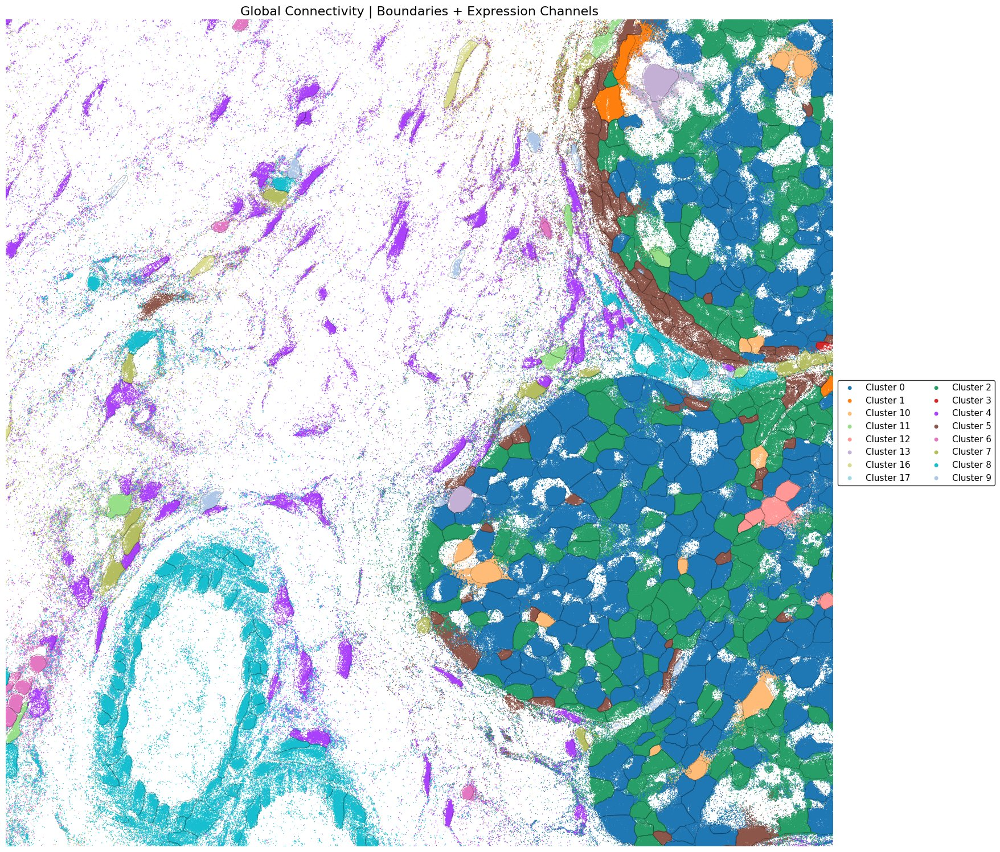

In [182]:
pl.spatial_transcripts_source(sdata, min_score=0.01, point_size=0.5,use_roi=True,roi=(4600,5000,2300,2700))
#plt.savefig('/home/icb/sergio.salas/notebooks/troutpy_reproducibility/uRNA_source_all.png', dpi=600, bbox_inches='tight', facecolor='white')
#plt.show()

(<Figure size 2500x2500 with 1 Axes>,
 <Axes: title={'center': 'Global Connectivity | Boundaries + Expression Channels'}>)

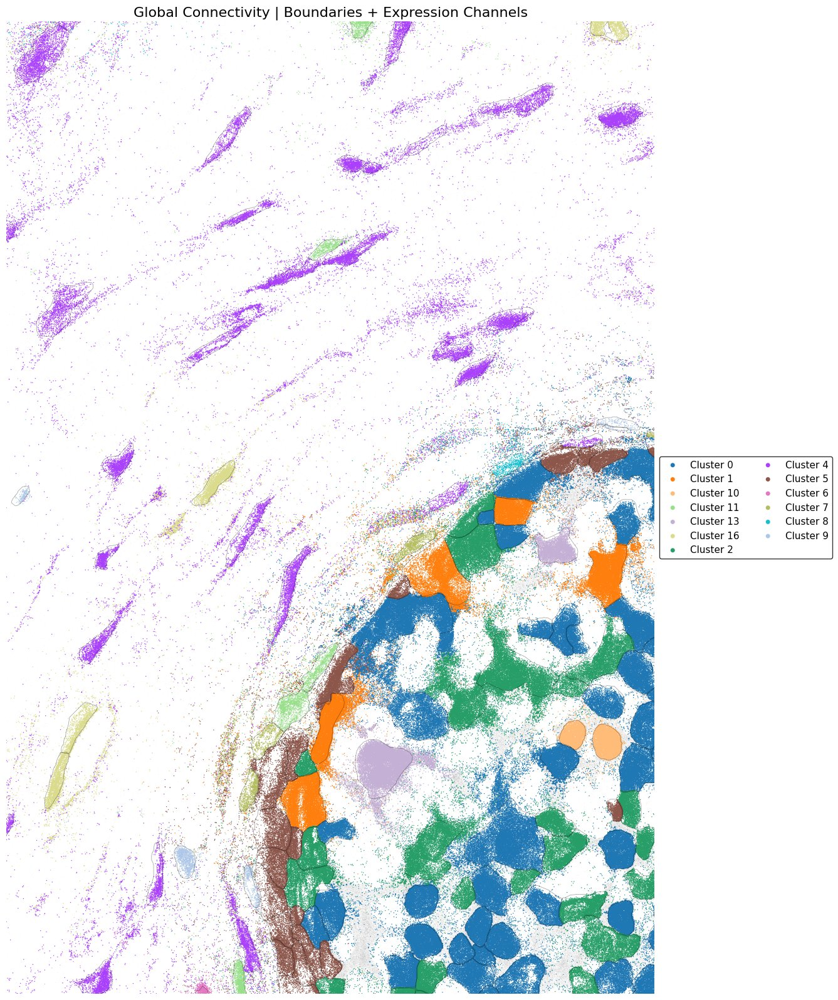

In [183]:
pl.spatial_transcripts_source(sdata, min_score=0.1, point_size=0.5,use_roi=True,roi=(4800,5000,2600,2900))
#plt.savefig('/home/icb/sergio.salas/notebooks/troutpy_reproducibility/uRNA_source_all.png', dpi=600, bbox_inches='tight', facecolor='white')
#plt.show()

(<Figure size 2500x2500 with 1 Axes>,
 <Axes: title={'center': 'Global Connectivity | Boundaries + Expression Channels'}>)

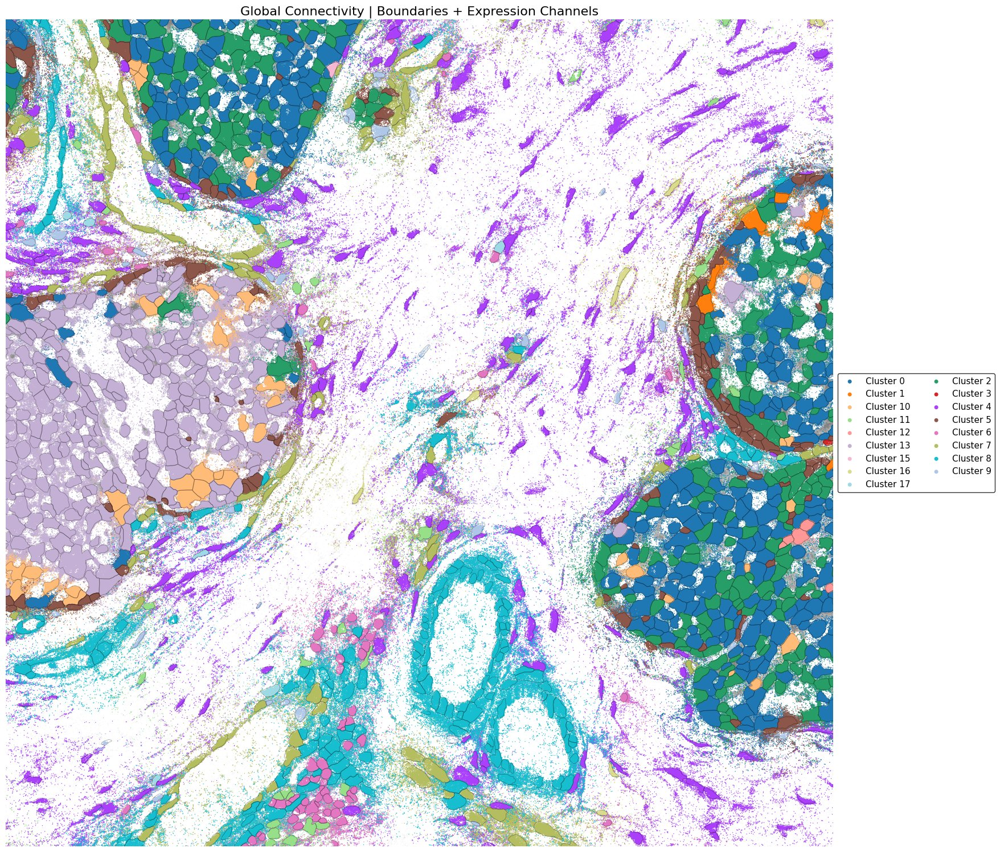

In [184]:
pl.spatial_transcripts_source(sdata, min_score=0.1, point_size=0.5,use_roi=True,roi=(4300,5000,2200,2900))
#plt.savefig('/home/icb/sergio.salas/notebooks/troutpy_reproducibility/uRNA_source_all.png', dpi=600, bbox_inches='tight', facecolor='white')
#plt.show()

(<Figure size 2500x2500 with 1 Axes>,
 <Axes: title={'center': 'Global Connectivity | Boundaries + Expression Channels'}>)

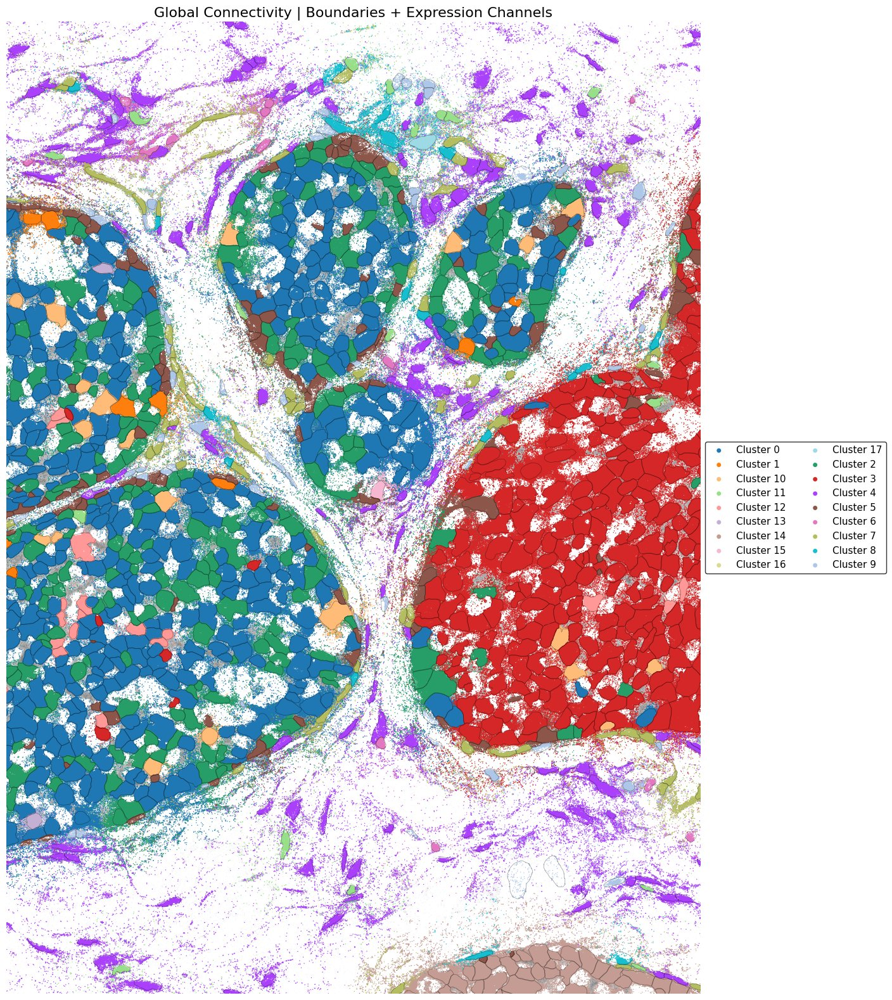

In [192]:
pl.spatial_transcripts_source(sdata, min_score=0.1, point_size=0.5,use_roi=True,roi=(5000,5500,2200,2900))
#plt.savefig('/home/icb/sergio.salas/notebooks/troutpy_reproducibility/uRNA_source_all.png', dpi=600, bbox_inches='tight', facecolor='white')
#plt.show()

In [190]:
sdata['source_score'].obs

,gene,predicted_parent,assignment_score,distance_to_source
7,B2M,bdjlifjm-1,0.042111,4.814554
8,A1BG,fggpfndi-1,0.055105,49.336239
10,A1BG,ffejaalp-1,0.220822,3.140586
12,A1BG,amlgghpk-1,0.070878,3.766403
24,RGMA,dnfpnmng-1,0.177681,28.505932
...,...,...,...,...
55991689,PMM2,becpejig-1,0.082938,2.115096
55991703,PMM2,bcldacna-1,0.072590,3.867464
55991715,PMM2,bedbhpjb-1,0.098371,3.133777
55991718,PMM2,ijmnkhcb-1,0.112850,5.732757


In [187]:
sdata['transcripts'].compute()

Index(['x', 'y', 'z', 'gene', 'cell_id', 'nucleus_distance',
       'overlaps_nucleus', 'codeword_index', 'qv', 'codeword_category',
       'fov_name', 'is_gene', 'transcript_id', 'control_probe',
       'overlaps_cell', 'enrichment_class', 'density_similarity_score',
       'enrichment_over_random', 'local_count_in_radius', 'closest_cell_type',
       'cosine_similarity', 'prob_is_urna', 'extracellular', 'point_source',
       'structure_id'],
      dtype='object')

In [ ]:
pl.metric_scatter(sdata,x='logfoldchange_over_noise',y='in_out_spearmanR',label_bottom_n_y=0,label_top_n_x=5,label_top_n_y=5,size=7,linewidth=0,figures_path=saving_path,custom_plot_filename='scatter_inout_logfoldratio.pdf')
pl.metric_scatter(sdata,x='moran_I',y='in_out_spearmanR',label_bottom_n_y=0,label_top_n_x=5,label_top_n_y=5,size=7,linewidth=0,figures_path=saving_path,custom_plot_filename='scatter_moranI_inout.pdf')
pl.metric_scatter(sdata,y='logfoldchange_over_noise',x='in_out_spearmanR',label_bottom_n_y=0,label_top_n_x=5,label_top_n_y=5,size=7,linewidth=0,figures_path=saving_path,custom_plot_filename='scatter_logfoldratio_inout.pdf')